# Experiment 08 — Coordination-weighted (3×) validation diagnostics

Evaluate **TensorNequIP-NMR-Coord3x-9083627**, the saved best checkpoint, on **50 validation structures only**. Training labels supply the elemental-mean baseline and shielding-coverage comparison; training predictions are not computed. No test dataset or old prediction cache is loaded.

The target is absolute isotropic magnetic shielding, `MS_Iso_QM = trace(ms)/3`, in ppm, one scalar per site. This is not a full-tensor or experimental chemical-shift evaluation.

These are development diagnostics for identifying improvements. This validation set already selected the checkpoint, so its errors and bootstrap intervals are not an independent final performance assessment. Bootstrap intervals are descriptive, conditional on this checkpoint and supplied split; they do not account for selection or training-seed variability.

Run all cells using the project's `.venv` Python. Existing model and dataset files are read only. All structure and atom indices are zero-based.


In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.utils.nn import count_used_parameters
from IPython.display import display, Markdown

RUN_NAME = 'TensorNequIP-NMR-Coord3x-9083627'
candidates = ([Path(os.environ['NEQUIP_PROJECT'])] if 'NEQUIP_PROJECT' in os.environ else [])
candidates += [Path.cwd(), *Path.cwd().parents,
               Path('/Users/louismcauliffe/code/research/NequIP_experiments')]
PROJECT = next((p.resolve() for p in candidates
                if (p / 'graph-pes-results' / RUN_NAME / 'model.pt').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set NEQUIP_PROJECT to the NequIP_experiments directory.')
sys.path.insert(0, str(PROJECT))
# Required to unpickle the trusted local model; importing does not generate data.
import nmr_helpers

RUN = PROJECT / 'graph-pes-results' / RUN_NAME
SPLITS = ['train', 'valid']
ELEMENTS = ['Si', 'O']
COLOURS = {'Si': '#2769a4', 'O': '#d56831'}
PATHS = {split: PROJECT / 'data/nmr_iso' / f'{split}.xyz' for split in SPLITS}
THREADS = 2
torch.set_num_threads(THREADS)
torch.set_default_dtype(torch.float32)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

def sha256(path):
    with open(path, 'rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

versions = {name: version(name) for name in ['graph-pes', 'torch', 'e3nn', 'ase', 'numpy', 'pandas']}
print('Project:', PROJECT)
print('Inference: CPU, float32,', THREADS, 'threads |', platform.machine())
print('Versions:', versions)


Project: /Users/louismcauliffe/code/research/NequIP_experiments
Inference: CPU, float32, 2 threads | arm64
Versions: {'graph-pes': '1.0.2', 'torch': '2.6.0', 'e3nn': '0.4.4', 'ase': '3.29.0', 'numpy': '2.4.6', 'pandas': '3.0.6'}


## 1. Checkpoint and training provenance

Check the exported model against `best.ckpt` before inference, including its saved offsets and scales. The final-epoch summary is not the best checkpoint's accuracy. Epoch numbers are displayed starting at one.


In [2]:
def same_state(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_state(v, b[k]) for k, v in a.items())
    if isinstance(a, (list, tuple)):
        return type(a) is type(b) and len(a) == len(b) and all(same_state(x, y) for x, y in zip(a, b))
    return a == b

config = yaml.safe_load((RUN / 'train-config.yaml').read_text())
summary = yaml.safe_load((RUN / 'summary.yaml').read_text())
best = torch.load(RUN / 'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
last = torch.load(RUN / 'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
model = torch.load(RUN / 'model.pt', map_location='cpu', weights_only=False)
best_state = {k.removeprefix('model.'): v for k, v in best['state_dict'].items() if k.startswith('model.')}
assert same_state(best_state, model.state_dict()), 'Export does not match best checkpoint.'
assert all(torch.isfinite(v).all() for v in best_state.values()
           if isinstance(v, torch.Tensor) and v.is_floating_point())
training_parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
model.eval().requires_grad_(False)
assert next(model.parameters()).dtype == torch.float32
best_epoch, last_epoch = int(best['epoch']) + 1, int(last['epoch']) + 1
loss_config = config['loss']['isotropy']['+coordination_loss.CoordinationWeightedMSE']
assert loss_config['defect_weight'] == 3.0 and loss_config['coordination_cutoff'] == 2.2
loss_weight = float(loss_config['weight'])
assert config['data'].get('test') is None
for split in ['train', 'valid']:
    assert config['data'][split]['property_map'] == {'MS_Iso_QM': 'tensor'}
    assert (PROJECT / config['data'][split]['path']).resolve() == PATHS[split].resolve()

provenance = {
    'Run': RUN_NAME, 'Best epoch (1-based)': best_epoch,
    'Last epoch (1-based)': last_epoch, 'Best global step': int(best['global_step']),
    'Export matches best checkpoint': True,
    'Learnable parameters': training_parameter_count,
    'Cutoff (Å)': float(model.cutoff), 'Training loss': f'{loss_weight:g} × coordination-weighted shielding MSE (defects 3×); validation unweighted',
    'Saved best validation MSE (ppm²)': float(summary['early_stopping/best_valid_loss']) / loss_weight,
    'Final-epoch validation MSE (ppm²)': float(summary['valid/metrics/coordination_mse']),
    'Physical batch size': config['fitting']['loader_kwargs']['batch_size'],
    'Gradient accumulation': config['fitting']['trainer_kwargs'].get('accumulate_grad_batches', 1),
}
display(pd.Series(provenance, name='Value').to_frame())
model_hash = sha256(RUN / 'model.pt')
del best, last, best_state


,Value
Run,TensorNequIP-NMR-Coord3x-9083627
Best epoch (1-based),287
Last epoch (1-based),300
Best global step,57400
Export matches best checkpoint,True
Learnable parameters,753262
Cutoff (Å),6.0
Training loss,1000 × coordination-weighted shielding MSE (de...
Saved best validation MSE (ppm²),3.409656
Final-epoch validation MSE (ppm²),3.633816


## 2. Audit training and validation labels

Check ppm units and every scalar label against `trace(ms)/3`. Screen for duplicate geometries within and between training and validation. Rounded coordinate fingerprints are not a symmetry-aware similarity search and cannot establish independence of related MD snapshots. Trajectory identifiers are unavailable.


In [3]:
structures = {split: read(path, index=':', format='extxyz') for split, path in PATHS.items()}
data_hashes = {split: sha256(path) for split, path in PATHS.items()}

def geometry_key(atoms):
    digest = hashlib.sha256()
    for array in [np.asarray(atoms.numbers, dtype='<i8'),
                  np.round(atoms.positions, 6).astype('<f8'),
                  np.round(atoms.cell.array, 6).astype('<f8'), atoms.pbc.astype('u1')]:
        digest.update(np.ascontiguousarray(array).tobytes())
    return digest.hexdigest()

audit_rows, fingerprint_sets = [], {}
for split, frames in structures.items():
    assert frames, f'Empty {split} split'
    max_trace_error = 0.0
    fingerprints = []
    for frame in frames:
        labels = np.asarray(frame.arrays['MS_Iso_QM'], dtype=np.float64)
        tensors = np.asarray(frame.arrays['ms'], dtype=np.float64).reshape(len(frame), 3, 3)
        expected = np.trace(tensors, axis1=1, axis2=2) / 3
        assert labels.shape == (len(frame),) and np.isfinite(labels).all()
        assert frame.info['magres_units']['ms'] == 'ppm'
        assert set(frame.get_chemical_symbols()) <= set(ELEMENTS)
        max_trace_error = max(max_trace_error, float(np.max(np.abs(labels - expected))))
        assert np.allclose(labels, expected, rtol=0, atol=1e-7)
        fingerprints.append(geometry_key(frame))
    fingerprint_sets[split] = set(fingerprints)
    row = {'split': split, 'structures': len(frames), 'sites': sum(map(len, frames)),
           'duplicate_frames': len(frames) - len(set(fingerprints)),
           'max_trace_error_ppm': max_trace_error}
    for element in ELEMENTS:
        row[element + '_sites'] = sum(np.sum(np.array(f.get_chemical_symbols()) == element) for f in frames)
    audit_rows.append(row)
audit = pd.DataFrame(audit_rows).set_index('split')
display(audit)
overlap = pd.DataFrame([{'split_A': a, 'split_B': b,
                         'shared_geometries': len(fingerprint_sets[a] & fingerprint_sets[b])}
                        for a, b in [('train', 'valid')]])
display(overlap)
assert overlap['shared_geometries'].sum() == 0, 'Split overlap: do not claim held-out accuracy.'
assert audit['duplicate_frames'].sum() == 0, 'Repeated structures need explicit treatment.'


,structures,sites,duplicate_frames,max_trace_error_ppm,Si_sites,O_sites
split,,,,,,
train,800,115200,0,3.333412e-09,38400,76800
valid,50,7200,0,3.333412e-09,2400,4800


,split_A,split_B,shared_geometries
0,train,valid,0


## 3. Fresh validation inference

Predict only the validation structures, using species, geometry and periodicity. Reference labels are excluded from model inputs. No fitting, referencing correction or cached predictions are used. Training labels are retained only for baseline and coverage calculations.


In [4]:
def predict_split(frames):
    predictions = []
    started = time.perf_counter()
    for index, atoms in enumerate(frames):
        graph = AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff))
        assert not graph.properties and not graph.other, 'Reference labels entered model inputs.'
        with torch.no_grad():
            values = model.predict(graph, ['tensor'])['tensor'].cpu().numpy().copy()
        assert values.shape == (len(atoms),) and np.isfinite(values).all()
        predictions.append(values)
        if (index + 1) % 100 == 0 or index + 1 == len(frames):
            print(f'{index + 1}/{len(frames)} structures complete', flush=True)
    return np.concatenate(predictions), time.perf_counter() - started

predictions, timings = {}, {}
with torch.no_grad():
    model.predict(AtomicGraph.from_ase(structures['valid'][0], cutoff=float(model.cutoff)), ['tensor'])
predictions['valid'], timings['valid'] = predict_split(structures['valid'])
rows = []
for split, frames in structures.items():
    start = 0
    for frame_index, atoms in enumerate(frames):
        count = len(atoms)
        rows.append(pd.DataFrame({
            'split': split, 'structure_index': frame_index, 'atom_index': np.arange(count),
            'element': atoms.get_chemical_symbols(),
            'reference_ppm': np.asarray(atoms.arrays['MS_Iso_QM'], dtype=np.float64),
            'prediction_ppm': predictions[split][start:start+count] if split == 'valid' else np.full(count, np.nan),
        }))
        start += count
sites = pd.concat(rows, ignore_index=True)
sites['error_ppm'] = sites['prediction_ppm'] - sites['reference_ppm']
sites['absolute_error_ppm'] = sites['error_ppm'].abs()
assert sites.loc[sites.split.eq('train'), 'prediction_ppm'].isna().all()
assert sites.loc[sites.split.eq('valid'), 'prediction_ppm'].notna().all()
print(f"Fresh validation inference: {timings['valid']:.2f} seconds for {len(structures['valid'])} structures.")


50/50 structures complete
Fresh validation inference: 15.70 seconds for 50 structures.


## 4. Site-level errors, reported separately for Si and O

For each element and split, $e_i=\hat\sigma_i-\sigma_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i e_i^2},\qquad
\mathrm{bias}=\frac{1}{n}\sum_i e_i.$$

$$R^2=1-\frac{\sum_i e_i^2}{\sum_i(\sigma_i-\bar\sigma)^2}.$$

Errors are in ppm; $R^2$ is dimensionless and is **not** squared Pearson correlation. Every site of the selected element contributes equally. The 95th percentile and maximum absolute errors show the tails. No outliers are removed.

The constant baseline uses **only the training-set mean of each element**. A percentage reduction in RMSE measures improvement over that baseline, not over a published ML model.


In [5]:
def score(reference, predicted):
    reference, predicted = np.asarray(reference, dtype=np.float64), np.asarray(predicted, dtype=np.float64)
    assert reference.shape == predicted.shape and reference.size > 0
    error = predicted - reference
    absolute = np.abs(error)
    denominator = np.sum((reference - reference.mean()) ** 2)
    result = {
        'MAE_ppm': float(absolute.mean()), 'RMSE_ppm': float(np.sqrt(np.mean(error ** 2))),
        'bias_ppm': float(error.mean()), 'median_AE_ppm': float(np.median(absolute)),
        'p95_AE_ppm': float(np.quantile(absolute, 0.95)), 'max_AE_ppm': float(absolute.max()),
        'R2': float(1 - np.sum(error ** 2) / denominator) if denominator > 0 else np.nan,
    }
    assert result['RMSE_ppm'] + 1e-12 >= result['MAE_ppm']
    return result

train_means = sites[sites['split'].eq('train')].groupby('element')['reference_ppm'].mean()
metric_rows = []
for split in ['valid']:
    for element in ELEMENTS:
        group = sites[sites['split'].eq(split) & sites['element'].eq(element)]
        scores = score(group['reference_ppm'], group['prediction_ppm'])
        baseline = score(group['reference_ppm'], np.full(len(group), train_means[element]))
        metric_rows.append({'split': split, 'element': element, 'sites': len(group),
                            'structures': group['structure_index'].nunique(), **scores,
                            'baseline_RMSE_ppm': baseline['RMSE_ppm'],
                            'baseline_MAE_ppm': baseline['MAE_ppm'],
                            'RMSE_reduction_vs_baseline_pct': 100 * (1 - scores['RMSE_ppm'] / baseline['RMSE_ppm'])})
metrics = pd.DataFrame(metric_rows).set_index(['split', 'element'])
print('Primary result — validation set:')
display(metrics.loc['valid'].round(4))
print('Validation errors by element:')
display(metrics[['MAE_ppm', 'RMSE_ppm', 'bias_ppm', 'R2']].round(4))
print('Training-only elemental-mean baseline (ppm):', train_means.round(4).to_dict())

# Check against the saved validation loss, which pools all sites and both elements.
pooled_mse = sites.groupby('split')['error_ppm'].agg(lambda x: float(np.mean(x.to_numpy() ** 2)))
logged_best_mse = float(summary['early_stopping/best_valid_loss']) / loss_weight
relative_discrepancy = abs(pooled_mse['valid'] - logged_best_mse) / logged_best_mse
assert relative_discrepancy < 0.005, 'Validation reconstruction differs from the saved best loss by >0.5%.'
print(f"Recomputed best validation MSE: {pooled_mse['valid']:.6f} ppm²; saved: {logged_best_mse:.6f} ppm²")
print(f'CPU versus training discrepancy: {100 * relative_discrepancy:.5f}%')
print('The training weight of 1000 is not applied to any accuracy metric above.')


Primary result — validation set:
Validation errors by element:
Training-only elemental-mean baseline (ppm): {'O': 201.5273, 'Si': 436.0872}
Recomputed best validation MSE: 3.409727 ppm²; saved: 3.409656 ppm²
CPU versus training discrepancy: 0.00207%
The training weight of 1000 is not applied to any accuracy metric above.


,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2,baseline_RMSE_ppm,baseline_MAE_ppm,RMSE_reduction_vs_baseline_pct
element,,,,,,,,,,,,
Si,2400,50,0.5295,0.9967,0.0224,0.3240,1.5962,12.9462,0.9879,9.0632,7.1323,89.0033
O,4800,50,1.0484,2.1489,0.0128,0.6079,3.2034,34.1242,0.9895,20.9806,14.0895,89.7575


MAE_ppm  RMSE_ppm  bias_ppm      R2
split element                                     
valid Si        0.5295    0.9967    0.0224  0.9879
      O         1.0484    2.1489    0.0128  0.9895

## 5. Descriptive validation sampling uncertainty

Resample 50 whole validation structures 2,000 times, keeping sites together. These percentile intervals describe sampling variation conditional on the selected model. They assume independent structures, exclude training-seed variability, and do not correct for using validation to select the checkpoint. They are not prediction intervals for individual sites.


In [6]:
validation_sites = sites[sites['split'].eq('valid')]
rng = np.random.default_rng(42)
bootstrap_rows = []
for element in ELEMENTS:
    group = validation_sites[validation_sites['element'].eq(element)]
    aggregate = group.groupby('structure_index')['error_ppm'].agg(
        n='size', sum_absolute=lambda x: float(np.abs(x).sum()),
        sum_squared=lambda x: float(np.square(x).sum()), sum_signed='sum')
    draws = rng.integers(0, len(aggregate), size=(2000, len(aggregate)))
    counts = aggregate['n'].to_numpy()[draws].sum(axis=1)
    boot_mae = aggregate['sum_absolute'].to_numpy()[draws].sum(axis=1) / counts
    boot_rmse = np.sqrt(aggregate['sum_squared'].to_numpy()[draws].sum(axis=1) / counts)
    boot_bias = aggregate['sum_signed'].to_numpy()[draws].sum(axis=1) / counts
    for metric, samples in [('MAE_ppm', boot_mae), ('RMSE_ppm', boot_rmse), ('bias_ppm', boot_bias)]:
        low, high = np.quantile(samples, [0.025, 0.975])
        bootstrap_rows.append({'element': element, 'metric': metric,
                               'estimate_ppm': metrics.loc[('valid', element), metric],
                               'lower_95_ppm': low, 'upper_95_ppm': high})
intervals = pd.DataFrame(bootstrap_rows).set_index(['element', 'metric'])
display(intervals.round(4))

def stats_box(ax, text, x=0.97, y=0.96, ha='right', fontsize=9):
    return ax.text(x, y, text, transform=ax.transAxes, va='top', ha=ha,
                   fontsize=fontsize, linespacing=1.45, zorder=10,
                   bbox={'facecolor': 'white', 'alpha': 0.94,
                         'edgecolor': '#d0d5db', 'boxstyle': 'round,pad=0.5'})

def ci_text(element, metric, signed=False):
    ci = intervals.loc[(element, metric)]
    fmt = '+.3f' if signed else '.3f'
    return f'{ci.lower_95_ppm:{fmt}} to {ci.upper_95_ppm:{fmt}}'


estimate_ppm  lower_95_ppm  upper_95_ppm
element metric                                            
Si      MAE_ppm         0.5295        0.4061        0.6880
        RMSE_ppm        0.9967        0.6017        1.3884
        bias_ppm        0.0224       -0.0163        0.0559
O       MAE_ppm         1.0484        0.8062        1.3354
        RMSE_ppm        2.1489        1.3587        2.9228
        bias_ppm        0.0128       -0.0765        0.1262

## 6. Validation-set parity and residuals

The parity diagonal is perfect agreement, not a fitted regression. Confidence intervals (CI) use the structure bootstrap above. Signed error is **prediction minus reference**: a positive bias means overprediction of shielding.

Histogram annotations give the bias with its confidence interval, residual standard deviation (SD, population definition), and median signed error. Residual-scatter annotations quantify tail errors. The largest 1% of absolute errors are highlighted; all sites remain included. Neither SD nor the 95th-percentile absolute error is a confidence interval.


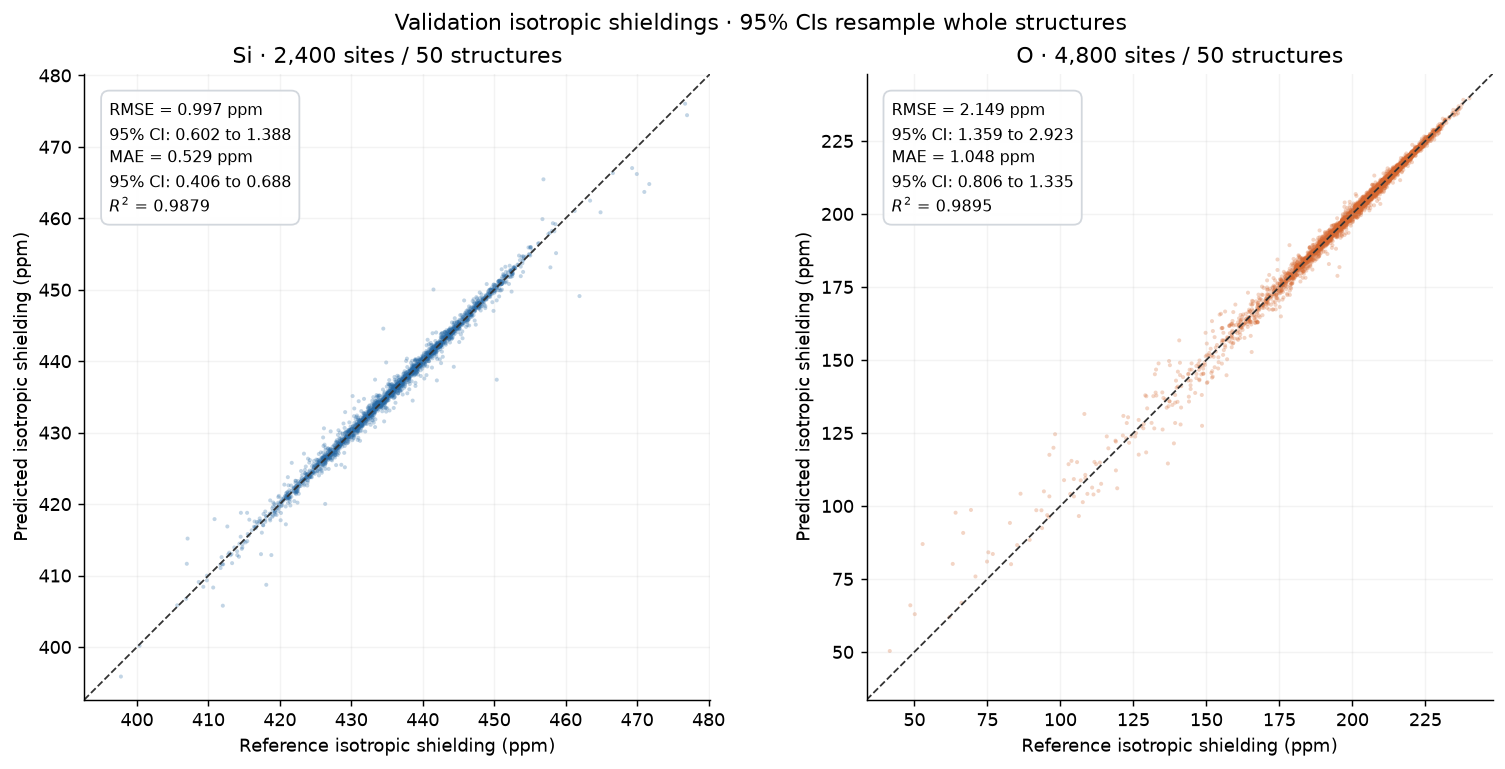

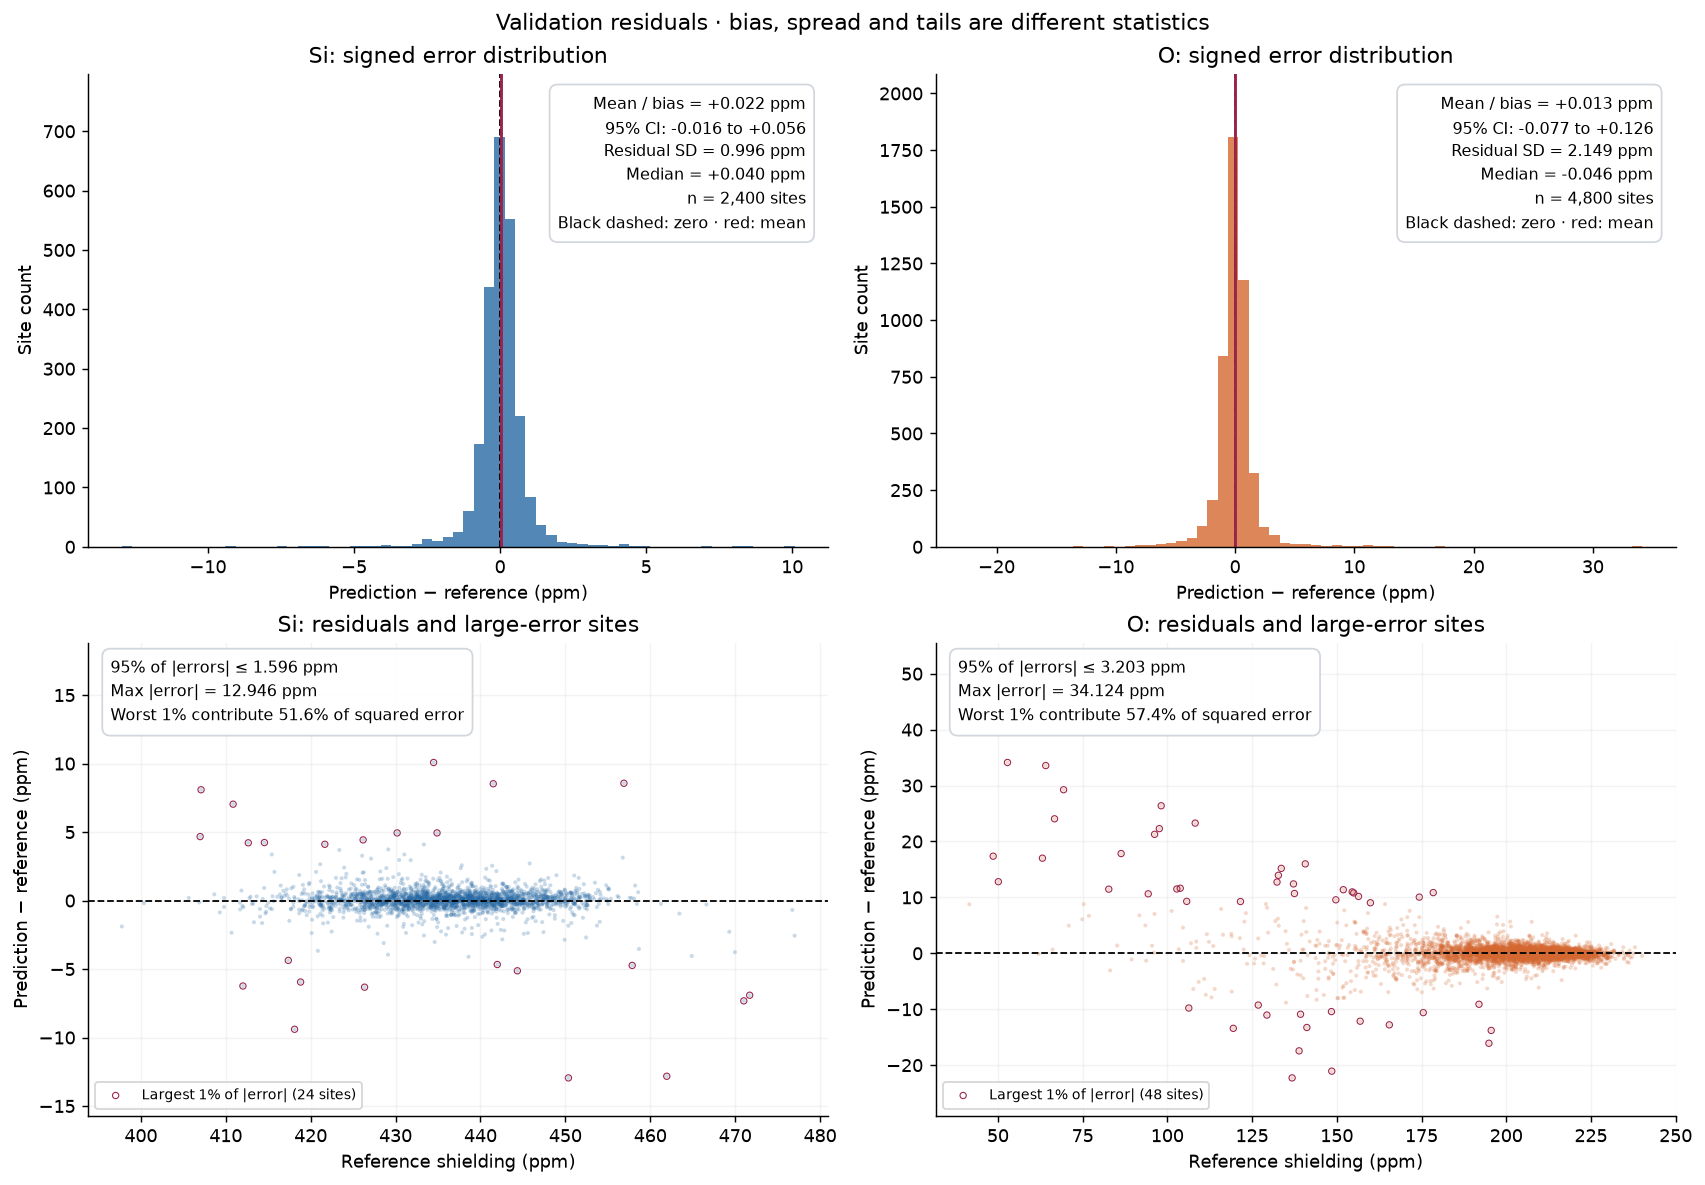

In [7]:
fig_parity, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = validation_sites[validation_sites['element'].eq(element)]
    ref, pred = group['reference_ppm'].to_numpy(), group['prediction_ppm'].to_numpy()
    low, high = min(ref.min(), pred.min()), max(ref.max(), pred.max())
    margin = max(0.04 * (high - low), 0.1)
    limits = [low - margin, high + margin]
    ax.scatter(ref, pred, s=5, alpha=0.28, color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.plot(limits, limits, '--', color='#333333', lw=1)
    ax.set(xlim=limits, ylim=limits, xlabel='Reference isotropic shielding (ppm)',
           ylabel='Predicted isotropic shielding (ppm)', title=f'{element} · {len(group):,} sites / {group.structure_index.nunique()} structures')
    ax.set_aspect('equal', adjustable='box')
    m = metrics.loc[('valid', element)]
    stats_box(ax, f'RMSE = {m.RMSE_ppm:.3f} ppm\n95% CI: {ci_text(element, "RMSE_ppm")}\n'
                 f'MAE = {m.MAE_ppm:.3f} ppm\n95% CI: {ci_text(element, "MAE_ppm")}\n'
                 f'$R^2$ = {m.R2:.4f}', x=0.04, ha='left')
    ax.grid(alpha=0.15)
fig_parity.suptitle('Validation isotropic shieldings · 95% CIs resample whole structures')
plt.show()

fig_residuals, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for column, element in enumerate(ELEMENTS):
    group = validation_sites[validation_sites['element'].eq(element)]
    error = group['error_ppm'].to_numpy()
    m = metrics.loc[('valid', element)]
    ax = axes[0, column]
    ax.hist(error, bins=65, color=COLOURS[element], alpha=0.8)
    ax.axvline(0, color='black', linestyle='--', lw=1)
    ax.axvline(m.bias_ppm, color='#9a244b', lw=1.6)
    stats_box(ax, f'Mean / bias = {m.bias_ppm:+.3f} ppm\n'
                 f'95% CI: {ci_text(element, "bias_ppm", signed=True)}\n'
                 f'Residual SD = {error.std(ddof=0):.3f} ppm\n'
                 f'Median = {np.median(error):+.3f} ppm\n'
                 f'n = {len(error):,} sites\nBlack dashed: zero · red: mean', fontsize=9)
    ax.set(title=f'{element}: signed error distribution', xlabel='Prediction − reference (ppm)', ylabel='Site count')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)

    ax = axes[1, column]
    tail_count = int(np.ceil(0.01 * len(error)))
    tail_positions = np.argsort(np.abs(error))[-tail_count:]
    tail_fraction = np.sum(error[tail_positions] ** 2) / np.sum(error ** 2)
    ax.scatter(group['reference_ppm'], error, s=5, alpha=0.25,
               color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.scatter(group['reference_ppm'].to_numpy()[tail_positions], error[tail_positions], s=12,
               facecolors='none', edgecolors='#9a244b', linewidths=0.6,
               label=f'Largest 1% of |error| ({tail_count} sites)', rasterized=True)
    ax.axhline(0, color='black', linestyle='--', lw=1)
    stats_box(ax, f'95% of |errors| ≤ {m.p95_AE_ppm:.3f} ppm\n'
                 f'Max |error| = {m.max_AE_ppm:.3f} ppm\n'
                 f'Worst 1% contribute {100 * tail_fraction:.1f}% of squared error',
              x=0.03, y=0.97, ha='left', fontsize=9)
    ax.set(title=f'{element}: residuals and large-error sites', xlabel='Reference shielding (ppm)',
           ylabel='Prediction − reference (ppm)')
    lo, hi = error.min(), error.max()
    ax.set_ylim(lo - 0.12 * (hi - lo), hi + 0.38 * (hi - lo))
    ax.legend(loc='lower left', fontsize=8)
    ax.grid(alpha=0.15)
fig_residuals.suptitle('Validation residuals · bias, spread and tails are different statistics')
plt.show()


## 7. Validation accuracy and shielding coverage

Compare validation errors with a constant predictor using each element's training mean. Compare training and validation label distributions without running predictions on training structures. Label-range overlap does not establish structural similarity.


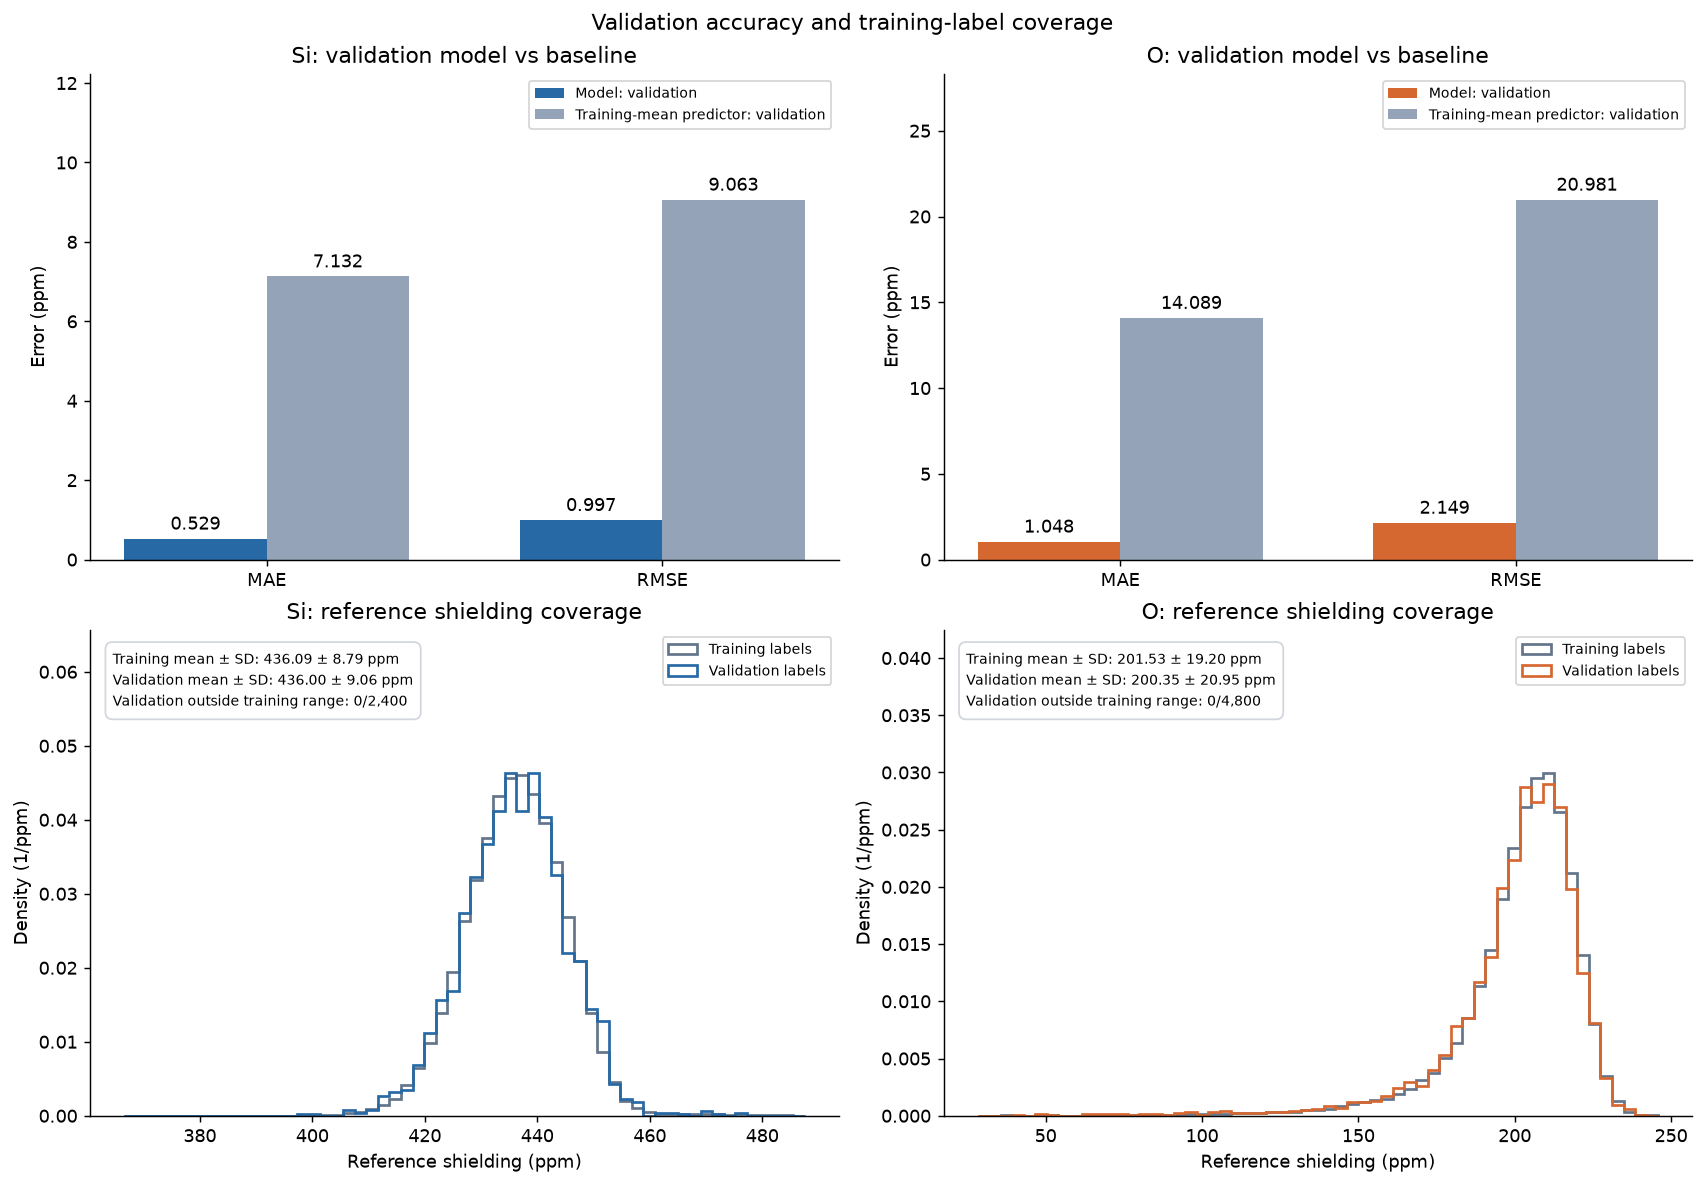

,train_min_ppm,train_max_ppm,validation_min_ppm,validation_max_ppm,validation_sites_outside_training_range
element,,,,,
Si,366.547,487.530,397.757,476.994,0
O,28.290,245.859,41.573,240.087,0


In [8]:
fig_splits, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
coverage_rows = []
for col, element in enumerate(ELEMENTS):
    ax = axes[0, col]
    m = metrics.loc[('valid', element)]
    x = np.arange(2)
    values = [m.MAE_ppm, m.RMSE_ppm]
    baseline = [m.baseline_MAE_ppm, m.baseline_RMSE_ppm]
    ax.bar(x-0.18, values, width=0.36, color=COLOURS[element], label='Model: validation')
    ax.bar(x+0.18, baseline, width=0.36, color='#94a3b8', label='Training-mean predictor: validation')
    for positions, numbers in [(x-0.18,values),(x+0.18,baseline)]:
        for pos, value in zip(positions,numbers):
            ax.annotate(f'{value:.3f}',(pos,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_xticks(x,['MAE','RMSE'])
    ax.set(title=f'{element}: validation model vs baseline',ylabel='Error (ppm)',ylim=(0,max(baseline+values)*1.35))
    ax.legend(fontsize=8)
    ax = axes[1,col]
    train = sites.loc[sites.split.eq('train') & sites.element.eq(element),'reference_ppm']
    valid = validation_sites.loc[validation_sites.element.eq(element),'reference_ppm']
    bins = np.linspace(min(train.min(),valid.min()),max(train.max(),valid.max()),60)
    for label, data, colour in [('Training labels',train,'#64748b'),('Validation labels',valid,COLOURS[element])]:
        ax.hist(data,bins=bins,density=True,histtype='step',lw=1.5,label=label,color=colour)
    outside = int(((valid<train.min()) | (valid>train.max())).sum())
    stats_box(ax,f'Training mean ± SD: {train.mean():.2f} ± {train.std(ddof=0):.2f} ppm\nValidation mean ± SD: {valid.mean():.2f} ± {valid.std(ddof=0):.2f} ppm\nValidation outside training range: {outside}/{len(valid):,}',x=0.03,ha='left',fontsize=8)
    ax.set(title=f'{element}: reference shielding coverage',xlabel='Reference shielding (ppm)',ylabel='Density (1/ppm)')
    ax.set_ylim(0,ax.get_ylim()[1]*1.35)
    ax.legend(loc='upper right',fontsize=8)
    coverage_rows.append({'element':element,'train_min_ppm':train.min(),'train_max_ppm':train.max(),
                         'validation_min_ppm':valid.min(),'validation_max_ppm':valid.max(),
                         'validation_sites_outside_training_range':outside})
fig_splits.suptitle('Validation accuracy and training-label coverage')
plt.show()
coverage = pd.DataFrame(coverage_rows).set_index('element')
display(coverage.round(3))


## 8. Structure-level variation and largest errors

Each point is one structure's RMSE. The dashed line gives RMSE across all validation sites; the shaded band is its 95% structure-bootstrap confidence interval. **The band is not a prediction interval for individual structures**: points outside it are not a test of statistical significance. Labels show the median and largest structure RMSE and identify the worst structure.

Overall site RMSE is computed from all squared site errors, not by averaging structure RMSEs. The table retains original structure/atom indices. No outliers are removed.


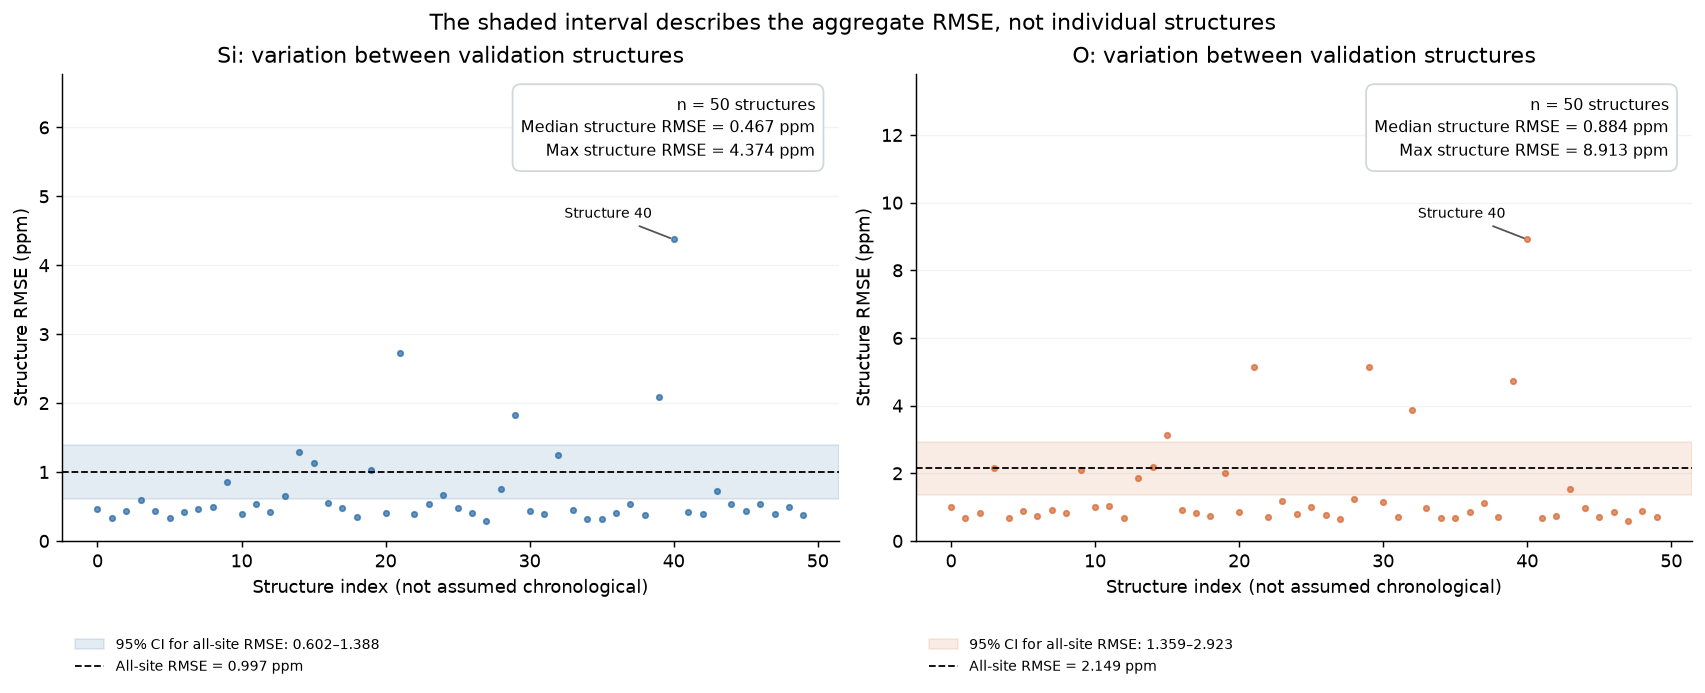

,element,structure_index,atom_index,reference_ppm,prediction_ppm,error_ppm
121073,Si,40,113,450.3575,437.4113,-12.9462
121088,Si,40,128,461.9409,449.1140,-12.8269
120957,Si,39,141,434.4809,444.5614,10.0805
118346,Si,21,122,418.1029,408.7057,-9.3972
121097,Si,40,137,456.8947,465.4573,8.5626
121055,O,40,95,52.8293,86.9535,34.1242
120977,O,40,17,64.1172,97.6885,33.5712
121032,O,40,72,69.3807,98.6327,29.2520
119464,O,29,88,98.1843,124.5695,26.3852
119895,O,32,87,66.7118,90.7653,24.0535


In [9]:
structure_rows = []
for (element, structure_index), group in validation_sites.groupby(['element', 'structure_index']):
    structure_rows.append({'element': element, 'structure_index': int(structure_index), 'sites': len(group),
                           **score(group['reference_ppm'], group['prediction_ppm'])})
structure_metrics = pd.DataFrame(structure_rows)
fig_structures, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = structure_metrics[structure_metrics['element'].eq(element)]
    aggregate = metrics.loc[('valid', element), 'RMSE_ppm']
    ci = intervals.loc[(element, 'RMSE_ppm')]
    worst = group.loc[group['RMSE_ppm'].idxmax()]
    ax.axhspan(ci.lower_95_ppm, ci.upper_95_ppm, color=COLOURS[element], alpha=0.12,
               label=f'95% CI for all-site RMSE: {ci.lower_95_ppm:.3f}–{ci.upper_95_ppm:.3f}')
    ax.plot(group['structure_index'], group['RMSE_ppm'], 'o', ms=3, alpha=0.7, color=COLOURS[element])
    ax.axhline(aggregate, color='black', ls='--', lw=1,
               label=f'All-site RMSE = {aggregate:.3f} ppm')
    stats_box(ax, f'n = {len(group)} structures\nMedian structure RMSE = {group.RMSE_ppm.median():.3f} ppm\n'
                 f'Max structure RMSE = {worst.RMSE_ppm:.3f} ppm', fontsize=9)
    dx = -12 if worst.structure_index > len(structures['valid'])/2 else 12
    ax.annotate(f'Structure {int(worst.structure_index)}', (worst.structure_index, worst.RMSE_ppm),
                xytext=(dx, 12), textcoords='offset points', fontsize=8,
                ha='right' if dx < 0 else 'left', arrowprops={'arrowstyle':'-', 'color':'#555555'})
    ax.set(title=f'{element}: variation between validation structures', xlabel='Structure index (not assumed chronological)',
           ylabel='Structure RMSE (ppm)', ylim=(0, worst.RMSE_ppm * 1.55))
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.18), fontsize=8, frameon=False)
    ax.grid(axis='y', alpha=0.15)
fig_structures.suptitle('The shaded interval describes the aggregate RMSE, not individual structures')
plt.show()
worst_sites = pd.concat([validation_sites[validation_sites['element'].eq(el)].nlargest(5, 'absolute_error_ppm') for el in ELEMENTS])
display(worst_sites[['element','structure_index','atom_index','reference_ppm','prediction_ppm','error_ppm']].round(4))


## 9. Does coordination explain the large errors?

Count oxygen neighbours around Si and silicon neighbours around O within **2.2 Å**, including periodic boundaries. The common groups are Si with four O neighbours and O with two Si neighbours. The observed neighbour counts for each group are reported below; groups are recomputed from validation structures.

The figure puts **site-level RMSE beside the number and percentage of sites** in each group. This separates the question “how frequent is this environment?” from “how accurate are its predictions?”. Whiskers are descriptive 95% confidence intervals from 2,000 whole-structure bootstrap resamples, retaining within-structure dependence. They assume independent structures and do not include training-seed uncertainty. Rare-group estimates have fewer supporting structures.

**Interpretation:** these are exploratory, distance-based groups, not definitive bonding assignments. A stretched bond near the cutoff can change the count. The association does not prove coordination itself causes the errors, and some normally coordinated sites also have large errors. All validation sites remain included; no model fitting uses these labels. Edit `COORDINATION_CUTOFF` below to check threshold sensitivity.


In [10]:
from ase.neighborlist import neighbor_list

COORDINATION_CUTOFF = 2.2  # Å; provisional geometric criterion, not a universal bond definition.
coordination_rows = []
for structure_index, atoms in enumerate(structures['valid']):
    centre, neighbour, distance = neighbor_list('ijd', atoms, COORDINATION_CUTOFF)
    unlike = (atoms.numbers[centre] != atoms.numbers[neighbour]) & (distance < COORDINATION_CUTOFF)
    counts = np.bincount(centre[unlike], minlength=len(atoms))
    coordination_rows.append(pd.DataFrame({
        'structure_index': structure_index, 'atom_index': np.arange(len(atoms)),
        'opposite_element_neighbours': counts,
    }))
coordination_sites = validation_sites.merge(pd.concat(coordination_rows, ignore_index=True),
                                      on=['structure_index', 'atom_index'], validate='one_to_one')
assert len(coordination_sites) == len(validation_sites)
coordination_sites['group'] = np.where(
    coordination_sites['opposite_element_neighbours'].eq(coordination_sites['element'].map({'Si': 4, 'O': 2})),
    'Common coordination', 'Other coordination')

# Resample full structures, including those with zero sites from a particular group.
coord_rng = np.random.default_rng(42)
n_structures = len(structures['valid'])
coord_draws = coord_rng.integers(0, n_structures, size=(2000, n_structures))
coordination_results = []
for element in ELEMENTS:
    element_sites = coordination_sites[coordination_sites['element'].eq(element)]
    for name in ['Common coordination', 'Other coordination']:
        group = element_sites[element_sites['group'].eq(name)]
        assert len(group) > 0, f'No {element} sites in {name} at this cutoff.'
        by_structure = group.groupby('structure_index')['error_ppm'].agg(
            n='size', squared_error=lambda x: float(np.square(x).sum()))
        by_structure = by_structure.reindex(np.arange(n_structures), fill_value=0)
        sample_counts = by_structure['n'].to_numpy()[coord_draws].sum(axis=1)
        sample_sse = by_structure['squared_error'].to_numpy()[coord_draws].sum(axis=1)
        nonempty = sample_counts > 0
        bootstrap_rmse = np.sqrt(sample_sse[nonempty] / sample_counts[nonempty])
        low, high = np.quantile(bootstrap_rmse, [0.025, 0.975])
        coordination_results.append({
            'element': element, 'group': name,
            'observed_neighbour_counts': ', '.join(map(str, sorted(group.opposite_element_neighbours.unique()))),
            'sites': len(group), 'percent_of_element_sites': 100 * len(group) / len(element_sites),
            'structures_containing_group': group.structure_index.nunique(),
            **score(group.reference_ppm, group.prediction_ppm),
            'RMSE_CI_lower_ppm': low, 'RMSE_CI_upper_ppm': high,
            'nonempty_bootstrap_resamples': int(nonempty.sum()),
        })
coordination_metrics = pd.DataFrame(coordination_results).set_index(['element', 'group'])
print(f'Validation-site coordination groups: unlike neighbours within {COORDINATION_CUTOFF:.1f} Å.')
display(coordination_metrics[['observed_neighbour_counts', 'sites', 'percent_of_element_sites',
                              'structures_containing_group', 'MAE_ppm', 'RMSE_ppm',
                              'RMSE_CI_lower_ppm', 'RMSE_CI_upper_ppm']].round(3))

# Keep the exact coordination categories visible rather than hiding them in the pooled groups.
coordination_detail = pd.DataFrame([
    {'element': element, 'neighbours': int(count), 'sites': len(group),
     'structures': group.structure_index.nunique(),
     'MAE_ppm': group.absolute_error_ppm.mean(),
     'RMSE_ppm': np.sqrt(np.mean(group.error_ppm ** 2))}
    for (element, count), group in coordination_sites.groupby(['element', 'opposite_element_neighbours'])
]).set_index(['element', 'neighbours'])


Validation-site coordination groups: unlike neighbours within 2.2 Å.


observed_neighbour_counts  sites  percent_of_element_sites  structures_containing_group  MAE_ppm  RMSE_ppm  RMSE_CI_lower_ppm  \
element group                                                                                                                                               
Si      Common coordination                         4   2386                    99.417                           50    0.501     0.849              0.592   
        Other coordination                          5     14                     0.583                            5    5.464     6.878              0.580   
O       Common coordination                         2   4762                    99.208                           50    1.003     1.933              1.264   
        Other coordination                       1, 3     38                     0.792                           13    6.801    10.726              4.978   

                             RMSE_CI_upper_ppm  
element group                                   
Si      Common coordination              1.096  
        Other coordination               8.362  
O       Common coordination              2.567  
        Other coordination              13.183

Exact coordination categories (small groups require caution):


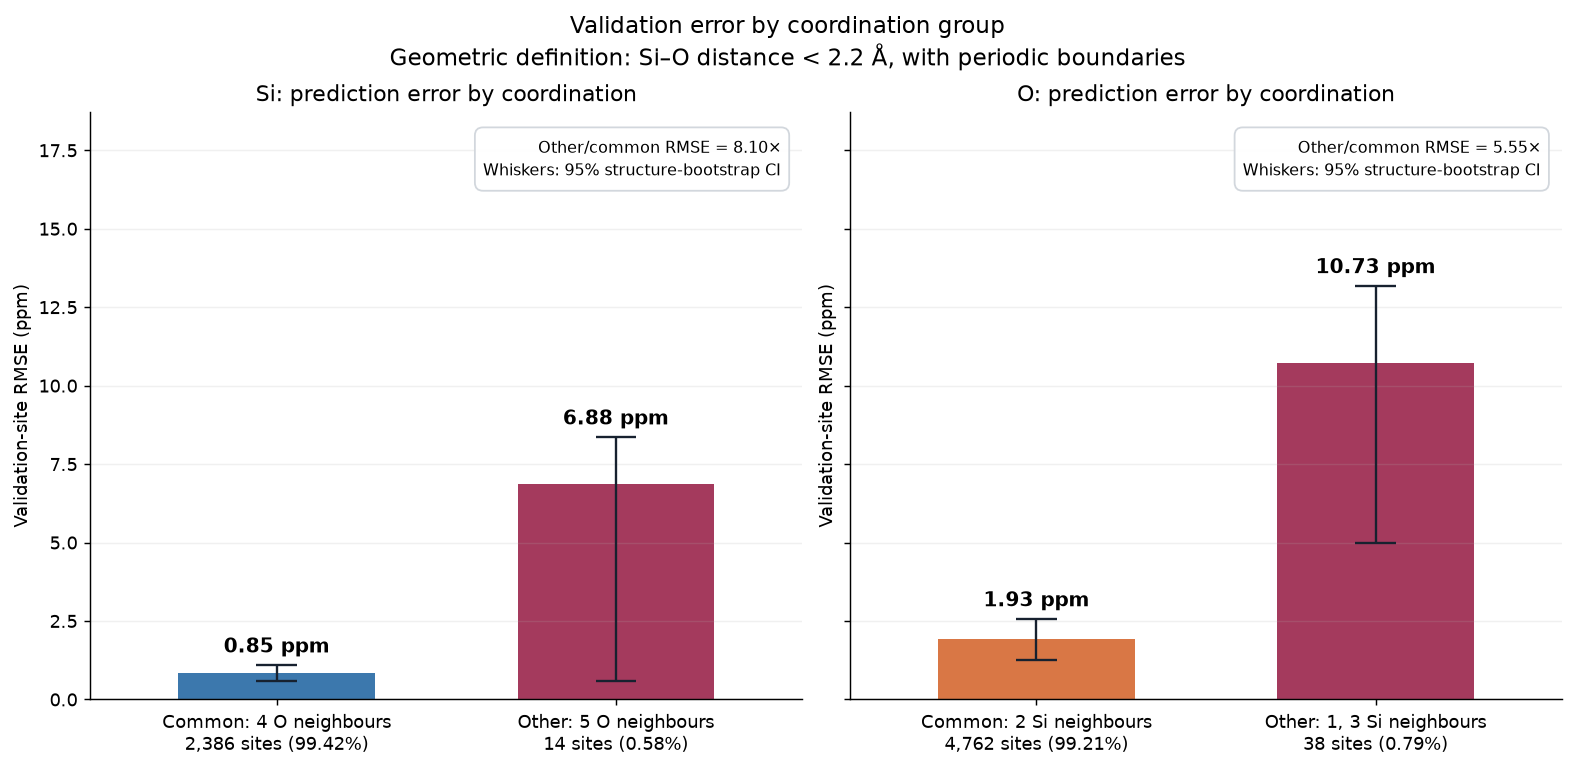

sites  structures  MAE_ppm  RMSE_ppm
element neighbours                                      
O       1              12          10   13.409    17.611
        2            4762          50    1.003     1.933
        3              26          13    3.751     5.001
Si      4            2386          50    0.501     0.849
        5              14           5    5.464     6.878

In [11]:
fig_coordination, axes = plt.subplots(1, 2, figsize=(12, 5.8), sharey=True, layout='constrained')
max_interval = coordination_metrics.RMSE_CI_upper_ppm.max()
for ax, element in zip(axes, ELEMENTS):
    table = coordination_metrics.loc[element].loc[['Common coordination', 'Other coordination']]
    values = table.RMSE_ppm.to_numpy()
    low, high = table.RMSE_CI_lower_ppm.to_numpy(), table.RMSE_CI_upper_ppm.to_numpy()
    positions = np.arange(2)
    ax.bar(positions, values, width=0.58, color=[COLOURS[element], '#9a244b'], alpha=0.9)
    # Draw percentile interval bounds directly (no assumption that they contain the point estimate).
    ax.vlines(positions, low, high, color='#17212f', linewidth=1.3)
    ax.hlines(low, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    ax.hlines(high, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    for x, value, upper in zip(positions, values, high):
        ax.annotate(f'{value:.2f} ppm', (x, max(value, upper)), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')
    neighbour = 'O' if element == 'Si' else 'Si'
    tick_labels = []
    for (_, row), kind in zip(table.iterrows(), ['Common', 'Other']):
        tick_labels.append(f'{kind}: {row.observed_neighbour_counts} {neighbour} neighbours\n'
                           f'{int(row.sites):,} sites ({row.percent_of_element_sites:.2f}%)')
    ax.set_xticks(positions, tick_labels, fontsize=10)
    ratio = values[1] / values[0]
    stats_box(ax, f'Other/common RMSE = {ratio:.2f}×\nWhiskers: 95% structure-bootstrap CI', fontsize=9)
    ax.set(title=f'{element}: prediction error by coordination', ylabel='Validation-site RMSE (ppm)',
           ylim=(0, max_interval * 1.42), xlim=(-0.55, 1.55))
    ax.grid(axis='y', alpha=0.18)
fig_coordination.suptitle(f'Validation error by coordination group\n'
                         f'Geometric definition: Si–O distance < {COORDINATION_CUTOFF:.1f} Å, with periodic boundaries',
                         fontsize=13)
plt.show()
print('Exact coordination categories (small groups require caution):')
display(coordination_detail.round(3))


## 10. Results and reproducibility record

These results quantify reproduction of the supplied **DFT isotropic shielding labels**. With a fixed reference and unit-magnitude sign conversion, shielding MAE/RMSE are unchanged when expressed as chemical-shift errors. A fitted slope would change their scale. No experimental referencing is estimated here.

Direct claims of superiority to published models would require the same nuclei, reference calculation settings, structural domain and validation split. The large Si/O baseline separation is why per-element results, rather than pooled correlation, are the headline.


In [12]:
lines = [f'**Best checkpoint: epoch {best_epoch} of {last_epoch}.** ',
         f"Validation evaluation: {len(structures['valid'])} structures and {len(validation_sites):,} atomic sites.", '']
for element in ELEMENTS:
    m = metrics.loc[('valid', element)]
    interval = intervals.loc[(element, 'RMSE_ppm')]
    lines.append(f"- **{element}:** MAE **{m.MAE_ppm:.3f} ppm**, RMSE **{m.RMSE_ppm:.3f} ppm**, "
                 f"bias {m.bias_ppm:+.3f} ppm, $R^2={m.R2:.4f}$. "
                 f"Structure-bootstrap RMSE interval: {interval.lower_95_ppm:.3f}–{interval.upper_95_ppm:.3f} ppm. "
                 f"RMSE is {m.RMSE_reduction_vs_baseline_pct:.1f}% below the elemental-mean baseline "
                 f"on the validation structures.")
lines += ['', 'These validation structures selected the checkpoint. Use these results for development, not as an independent final assessment. No test dataset was loaded.']
display(Markdown('\n'.join(lines)))

manifest = {
    'evaluation_utc': datetime.now(timezone.utc).isoformat(),
    'run': RUN_NAME, 'best_epoch_1based': best_epoch, 'last_epoch_1based': last_epoch,
    'target': 'MS_Iso_QM = trace(ms)/3; absolute isotropic shielding', 'units': 'ppm',
    'error_sign': 'prediction minus reference', 'reference': 'CASTEP/PBE labels in supplied XYZ files',
    'model_sha256': model_hash, 'best_checkpoint_sha256': sha256(RUN / 'checkpoints/best.ckpt'),
    'config_sha256': sha256(RUN / 'train-config.yaml'),
    'helper_sha256': sha256(PROJECT / 'nmr_helpers/extract_ms_isotropy.py'),
    'data_sha256': data_hashes, 'versions': versions, 'python': platform.python_version(),
    'device': 'cpu', 'dtype': 'float32 predictions; float64 metrics', 'torch_threads': THREADS,
    'site_counts': audit['sites'].to_dict(), 'structure_counts': audit['structures'].to_dict(),
    'bootstrap': {'unit': 'structure', 'resamples': 2000, 'seed': 42,
                  'limitation': 'Assumes independent structures; trajectory dependence not assessed.'},
    'coordination_diagnostic': {'cutoff_A': COORDINATION_CUTOFF, 'periodic': True,
        'groups': 'Si: 4 versus other O neighbours; O: 2 versus other Si neighbours',
        'split': 'valid', 'bootstrap_resamples': 2000, 'seed': 42},
    'corrections_applied': False, 'outliers_removed': False,
}
print(json.dumps(manifest, indent=2))
print('Tables remain available as metrics, sites, structure_metrics, intervals and audit.')


{
  "evaluation_utc": "2026-10-14T14:45:04.741610+00:00",
  "run": "TensorNequIP-NMR-Coord3x-9083627",
  "best_epoch_1based": 287,
  "last_epoch_1based": 300,
  "target": "MS_Iso_QM = trace(ms)/3; absolute isotropic shielding",
  "units": "ppm",
  "error_sign": "prediction minus reference",
  "reference": "CASTEP/PBE labels in supplied XYZ files",
  "model_sha256": "e6b96cb04593adc1761b682a0d070a34c49c3de329493ef39016074ca6b625e6",
  "best_checkpoint_sha256": "64f652c9275f83519bfb5f92eaf771e82d44920cac39fb1c88324a4f242b4199",
  "config_sha256": "937013dd35accfa52183d1399e78b7c924bdd80094569b3d336f61ce46088063",
  "helper_sha256": "4847dab4b6cbf7375eecdad2fe8aa68dc9b919b3e993e96d27f03c976c53a3cc",
  "data_sha256": {
    "train": "77de1ed9983781e906c35aa63d4f134a0777c6e38a933791c6db866f8b9c6fda",
    "valid": "e73ce6065ce6729d6549d5b30a4129634aaec84e3a2429c044d31d81020a4d11"
  },
  "versions": {
    "graph-pes": "1.0.2",
    "torch": "2.6.0",
    "e3nn": "0.4.4",
    "ase": "3.29.0",
   

**Best checkpoint: epoch 287 of 300.** 
Validation evaluation: 50 structures and 7,200 atomic sites.

- **Si:** MAE **0.529 ppm**, RMSE **0.997 ppm**, bias +0.022 ppm, $R^2=0.9879$. Structure-bootstrap RMSE interval: 0.602–1.388 ppm. RMSE is 89.0% below the elemental-mean baseline on the validation structures.
- **O:** MAE **1.048 ppm**, RMSE **2.149 ppm**, bias +0.013 ppm, $R^2=0.9895$. Structure-bootstrap RMSE interval: 1.359–2.923 ppm. RMSE is 89.8% below the elemental-mean baseline on the validation structures.

These validation structures selected the checkpoint. Use these results for development, not as an independent final assessment. No test dataset was loaded.

## 11. Experiment 07 versus 08: reproducible paired comparisons

The following figures rerun the **original experiment-07 model** on exactly the same validation geometries. All comparisons use **ordinary, unweighted errors in ppm**, not the different training objectives. The models are compared at their respective selected best checkpoints (07: epoch 188; 08: epoch 287). The differing selected epochs are part of the training outcome, not a fixed-epoch isolation of the weighting effect. No additional training takes place here.

**Percentage reduction = 100 × (07 error − 08 error) / 07 error.** Positive reductions mean lower error. Figure A separates average, typical and extreme errors; Figure B shows the pooled defect-group RMSE changes. These bars are descriptive point estimates; a paired structure-bootstrap comparison follows in Figure G.


{
  "baseline_model_sha256": "f2159b2fe9bd80147c46b55413c233cd616d825c976e75bf80de345f4104b32a",
  "baseline_best_epoch": 188,
  "coord3x_best_epoch": 287,
  "validation_sha256": "e73ce6065ce6729d6549d5b30a4129634aaec84e3a2429c044d31d81020a4d11",
  "evaluation": "Fresh, unweighted, paired predictions on identical validation sites; no test data.",
  "percentage_definition": "100 * (old - new) / old; positive means improvement"
}


MAE_ppm_3x  RMSE_ppm_3x  median_AE_ppm_3x  p95_AE_ppm_3x  max_AE_ppm_3x  bias_ppm_3x  MAE_ppm_original  RMSE_ppm_original  \
split element                                                                                                                              
valid Si           0.5295       0.9967            0.3240         1.5962        12.9462       0.0224            0.5378             1.0968   
      O            1.0484       2.1489            0.6079         3.2034        34.1242       0.0128            1.0712             2.2350   

               median_AE_ppm_original  p95_AE_ppm_original  max_AE_ppm_original  bias_ppm_original  RMSE_change_pct  
split element                                                                                                        
valid Si                       0.3153               1.6081              16.1388            -0.0580          -9.1288  
      O                        0.6044               3.5174              42.0414             0.1312          -3.8491

sites  MAE_ppm_3x  RMSE_ppm_3x  MAE_ppm_original  RMSE_ppm_original  RMSE_change_pct
element group                                                                                                    
Si      Common coordination   2386      0.5005       0.8495            0.5004             0.8838          -3.8906
        Other coordination      14      5.4637       6.8780            6.9154             8.5487         -19.5433
O       Common coordination   4762      1.0025       1.9331            1.0183             1.9436          -0.5411
        Other coordination      38      6.8010      10.7262            7.6947            12.5531         -14.5531

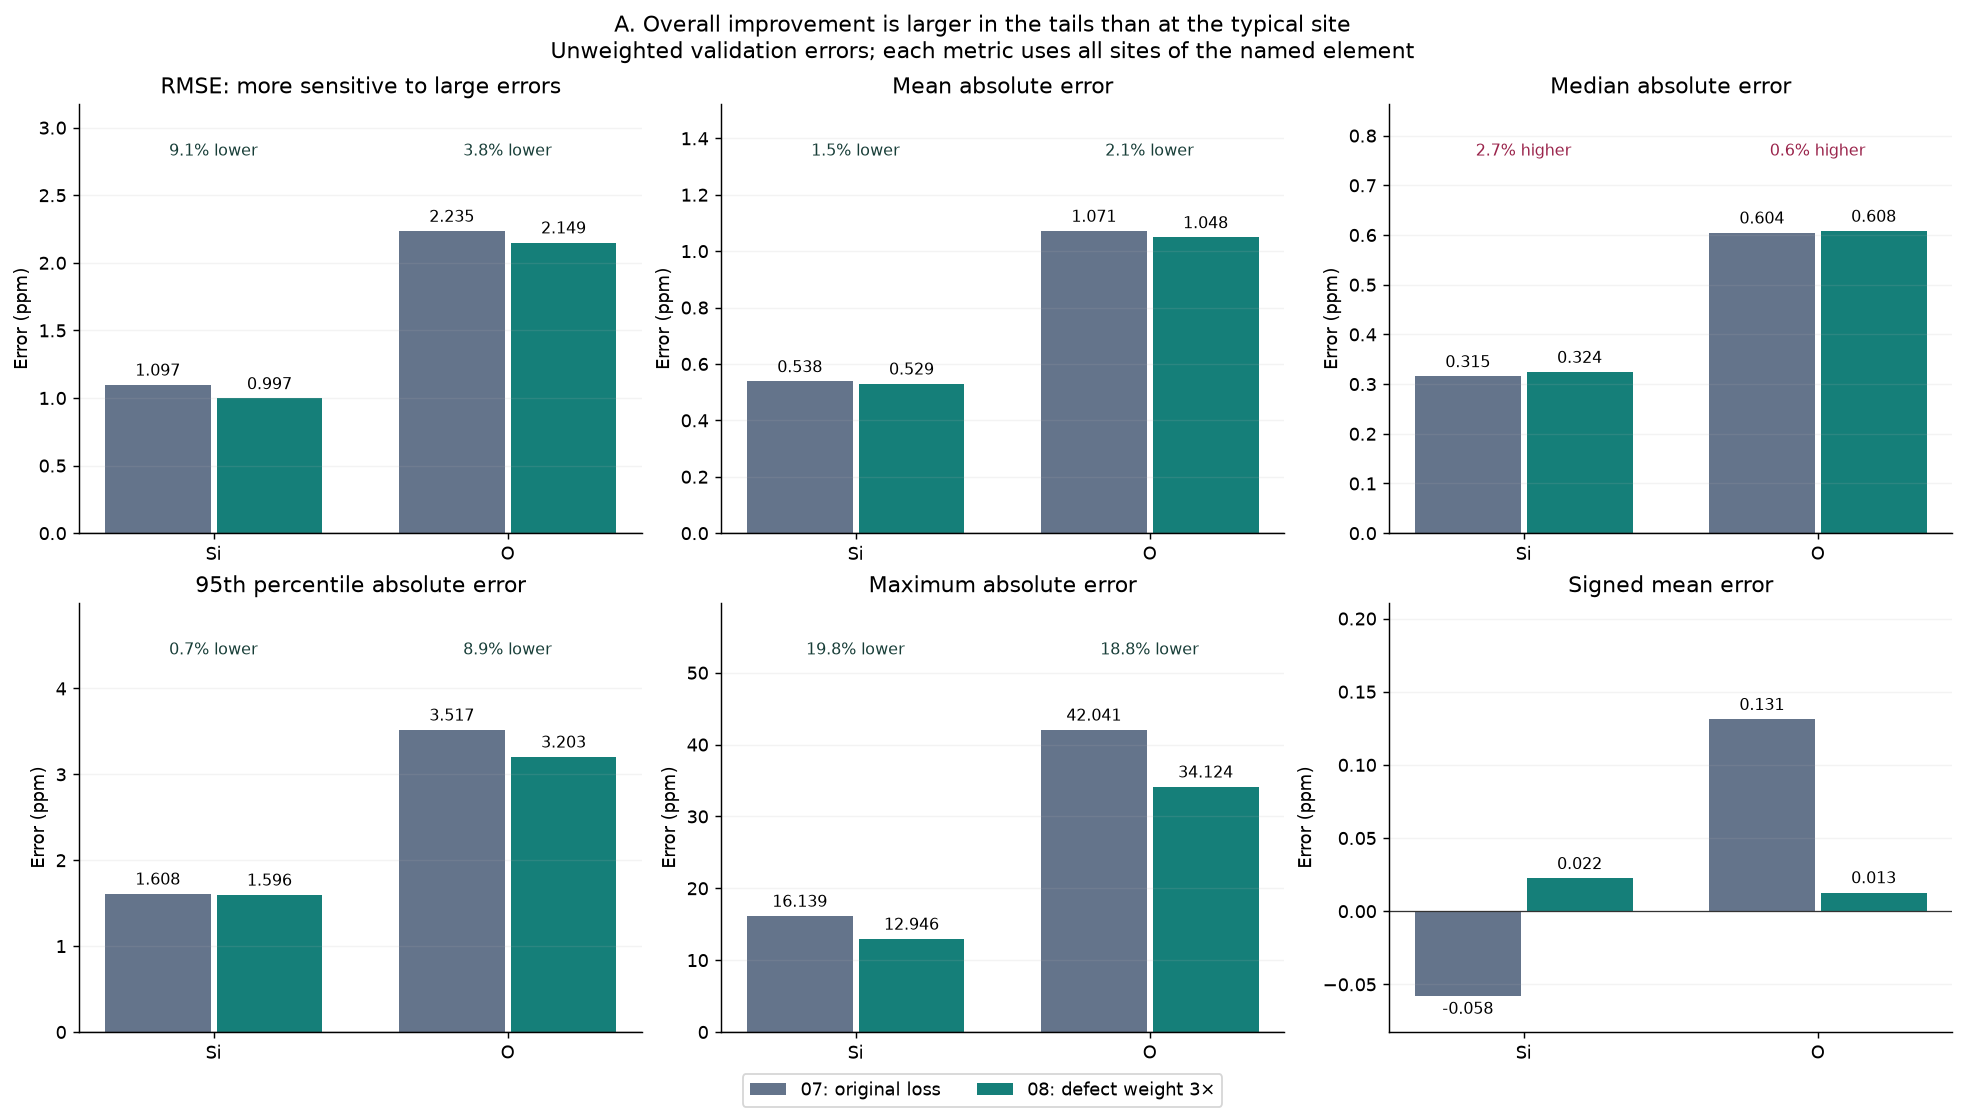

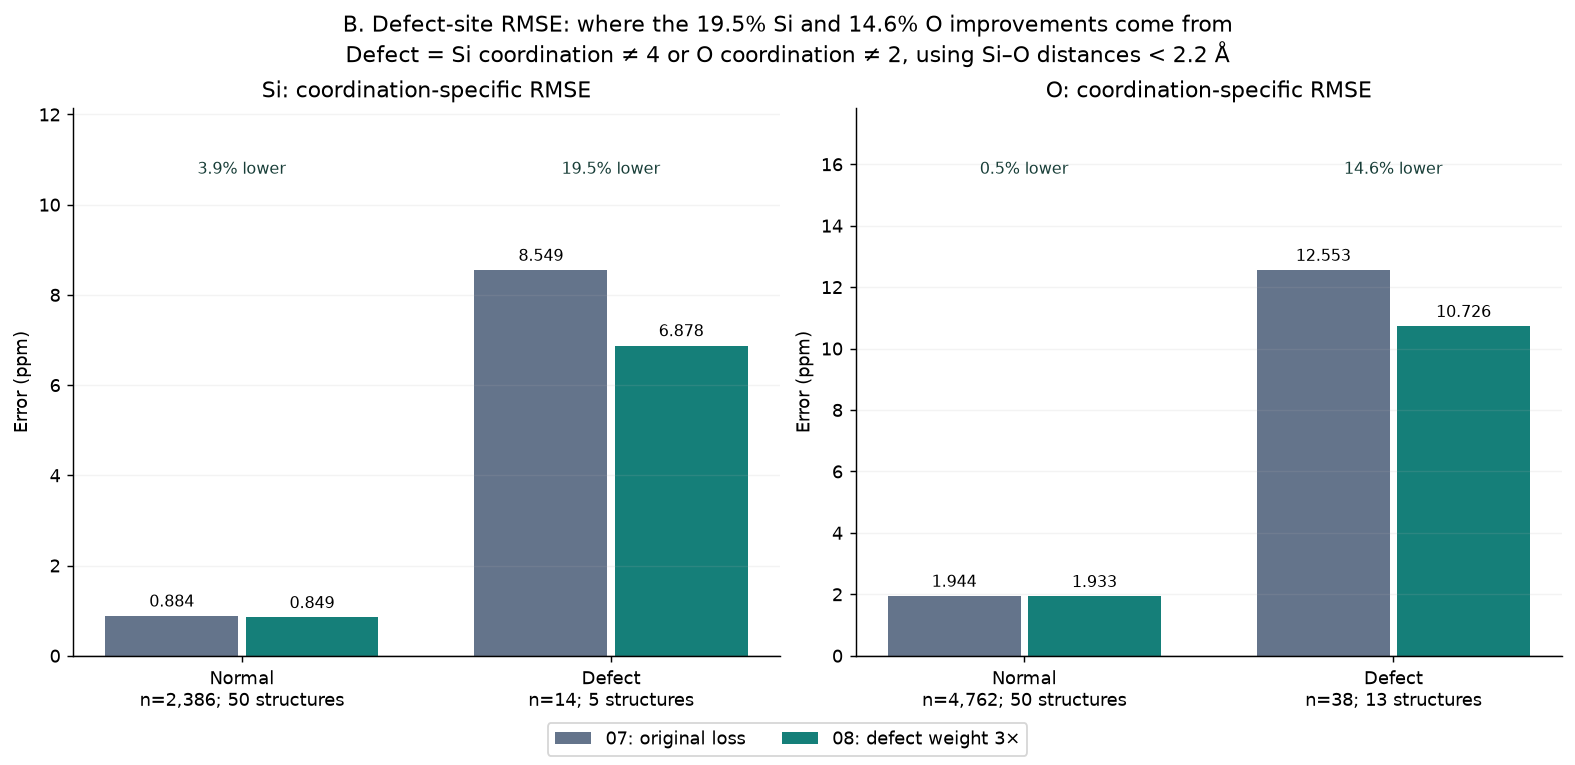

In [13]:
# Recompute experiment 07 on exactly the same validation geometries.
BASELINE_RUN = PROJECT / 'graph-pes-results/TensorNequIP-NMR-9065266'
baseline_model = torch.load(BASELINE_RUN / 'model.pt', map_location='cpu', weights_only=False)
baseline_checkpoint = torch.load(BASELINE_RUN / 'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
assert same_state({k.removeprefix('model.'):v for k,v in baseline_checkpoint['state_dict'].items()
                   if k.startswith('model.')}, baseline_model.state_dict())
baseline_epoch = int(baseline_checkpoint['epoch']) + 1
baseline_model.eval().requires_grad_(False)
baseline_predictions = []
for atoms in structures['valid']:
    graph = AtomicGraph.from_ase(atoms, cutoff=float(baseline_model.cutoff))
    assert not graph.properties and not graph.other
    with torch.no_grad():
        values = baseline_model.predict(graph, ['tensor'])['tensor'].cpu().numpy().copy()
    assert values.shape == (len(atoms),) and np.isfinite(values).all()
    baseline_predictions.append(values)
baseline_sites = coordination_sites.copy()
baseline_sites['prediction_ppm'] = np.concatenate(baseline_predictions)
baseline_sites['error_ppm'] = baseline_sites.prediction_ppm - baseline_sites.reference_ppm
baseline_sites['absolute_error_ppm'] = baseline_sites.error_ppm.abs()
assert len(baseline_sites) == len(coordination_sites) == 7200
baseline_metrics = pd.DataFrame([
    {'split':'valid','element':el,**score(g.reference_ppm,g.prediction_ppm)}
    for el,g in baseline_sites.groupby('element')]).set_index(['split','element'])
baseline_coordination = pd.DataFrame([
    {'element':el,'group':name,'sites':len(g),**score(g.reference_ppm,g.prediction_ppm)}
    for (el,name),g in baseline_sites.groupby(['element','group'])]).set_index(['element','group'])
baseline_detail = pd.DataFrame([
    {'element':el,'neighbours':int(c),'sites':len(g),**score(g.reference_ppm,g.prediction_ppm)}
    for (el,c),g in baseline_sites.groupby(['element','opposite_element_neighbours'])]).set_index(['element','neighbours'])
comparison_fields = ['MAE_ppm','RMSE_ppm','median_AE_ppm','p95_AE_ppm','max_AE_ppm','bias_ppm']
comparison = metrics[comparison_fields].join(baseline_metrics[comparison_fields],lsuffix='_3x',rsuffix='_original')
comparison['RMSE_change_pct'] = 100*(comparison.RMSE_ppm_3x/comparison.RMSE_ppm_original-1)
coordination_comparison = coordination_metrics[['sites','MAE_ppm','RMSE_ppm']].join(
    baseline_coordination[['MAE_ppm','RMSE_ppm']],lsuffix='_3x',rsuffix='_original')
coordination_comparison['RMSE_change_pct'] = 100*(coordination_comparison.RMSE_ppm_3x/coordination_comparison.RMSE_ppm_original-1)
baseline_summary = yaml.safe_load((BASELINE_RUN/'summary.yaml').read_text())
assert np.isclose(np.mean(baseline_sites.error_ppm**2),baseline_summary['early_stopping/best_valid_loss']/1000,rtol=0.005)
comparison_manifest = {'baseline_model_sha256':sha256(BASELINE_RUN/'model.pt'),
    'baseline_best_epoch':baseline_epoch,'coord3x_best_epoch':best_epoch,'validation_sha256':data_hashes['valid'],
    'evaluation':'Fresh, unweighted, paired predictions on identical validation sites; no test data.',
    'percentage_definition':'100 * (old - new) / old; positive means improvement'}
print(json.dumps(comparison_manifest,indent=2))
display(comparison.round(4))
display(coordination_comparison.round(4))
del baseline_checkpoint, baseline_model
OLD, NEW = '#64748b', '#157f79'
RUN_LABELS = ['07: original loss','08: defect weight 3×']

def paired_bars(ax, labels, old, new, title, ylabel='Error (ppm)', changes=True):
    old,new = np.asarray(old),np.asarray(new)
    x=np.arange(len(labels))
    for shift,vals,color,label in [(-.19,old,OLD,RUN_LABELS[0]),(.19,new,NEW,RUN_LABELS[1])]:
        bars=ax.bar(x+shift,vals,.36,color=color,label=label)
        ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=9)
    ax.set_xticks(x,labels);ax.set_title(title);ax.set_ylabel(ylabel)
    ax.axhline(0,color='#333333',lw=.7);ax.grid(axis='y',alpha=.15)
    low=min(0,float(min(old.min(),new.min())))
    high=max(float(max(old.max(),new.max())),.01)
    span=high-low
    ax.set_ylim(low-.13*span if low<0 else 0,high+.42*span)
    if changes:
        for i,(a,b) in enumerate(zip(old,new)):
            reduction=100*(a-b)/a
            ax.text(i,high+.25*span,f'{abs(reduction):.1f}% '+('lower' if reduction>=0 else 'higher'),
                    ha='center',fontsize=9,color='#183e38' if reduction>=0 else '#9a244b')

fig,axes=plt.subplots(2,3,figsize=(15,8.5),layout='constrained')
for ax,(key,title) in zip(axes.flat,[('RMSE_ppm','RMSE: more sensitive to large errors'),
    ('MAE_ppm','Mean absolute error'),('median_AE_ppm','Median absolute error'),
    ('p95_AE_ppm','95th percentile absolute error'),('max_AE_ppm','Maximum absolute error'),('bias_ppm','Signed mean error')]):
    paired_bars(ax,ELEMENTS,baseline_metrics.loc['valid'].loc[ELEMENTS,key],metrics.loc['valid'].loc[ELEMENTS,key],title,changes=key!='bias_ppm')
fig.legend(*axes.flat[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('A. Overall improvement is larger in the tails than at the typical site\nUnweighted validation errors; each metric uses all sites of the named element')
plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,5.8),layout='constrained')
for ax,el in zip(axes,ELEMENTS):
    groups=['Common coordination','Other coordination']
    a=baseline_coordination.loc[el].loc[groups];b=coordination_metrics.loc[el].loc[groups]
    labels=[f'{name}\nn={int(row.sites):,}; {int(row.structures_containing_group)} structures'
            for name,(_,row) in zip(['Normal','Defect'],b.iterrows())]
    paired_bars(ax,labels,a.RMSE_ppm,b.RMSE_ppm,f'{el}: coordination-specific RMSE')
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle(f'B. Defect-site RMSE: where the {-coordination_comparison.loc[("Si","Other coordination"),"RMSE_change_pct"]:.1f}% Si and {-coordination_comparison.loc[("O","Other coordination"),"RMSE_change_pct"]:.1f}% O improvements come from\nDefect = Si coordination ≠ 4 or O coordination ≠ 2, using Si–O distances < 2.2 Å')
plt.show()


## 12. Locate the benefit and the remaining error

**Figure C** uses sums of squared errors (SSE), not averages of subgroup RMSE. For each element:

- Remaining group error share = group SSE / total SSE.
- Group contribution to the improvement = (group SSE₀₇ − group SSE₀₈) / (total SSE₀₇ − total SSE₀₈).

These percentages have different denominators and answer different questions. Normal atoms are far more numerous, so their high share of remaining error does not mean they are individually harder than defect atoms. **Figure D** separates exact coordination counts; O1 and O3 should not be treated as equally difficult merely because both are assigned weight 3.


,run,element,group,sites,SSE_ppm2,percent_of_element_SSE
0,07,O,Common coordination,4762,17988.277,75.025
1,07,O,Other coordination,38,5988.020,24.975
2,07,Si,Common coordination,2386,1863.866,64.561
3,07,Si,Other coordination,14,1023.120,35.439
4,08,O,Common coordination,4762,17794.130,80.276
5,08,O,Other coordination,38,4371.954,19.724
6,08,Si,Common coordination,2386,1721.656,72.219
7,08,Si,Other coordination,14,662.294,27.781


run                                 07         08  SSE_reduction  percent_of_element_reduction
element group                                                                                 
O       Common coordination  17988.277  17794.130        194.147                        10.725
        Other coordination    5988.020   4371.954       1616.065                        89.275
Si      Common coordination   1863.866   1721.656        142.210                        28.270
        Other coordination    1023.120    662.294        360.826                        71.730

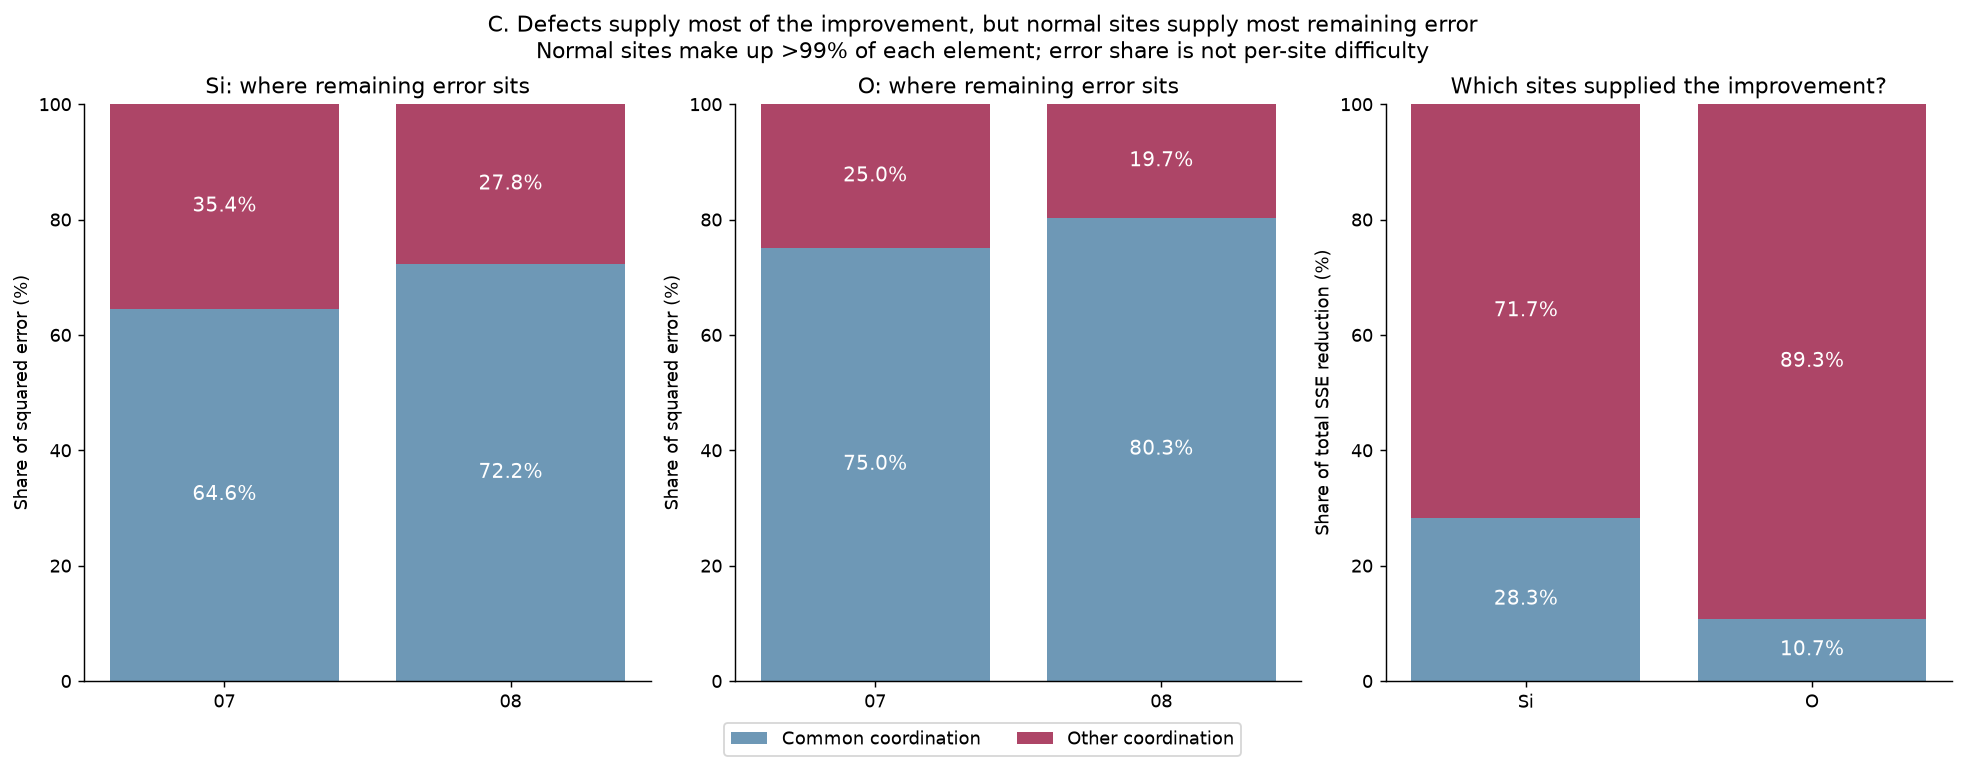

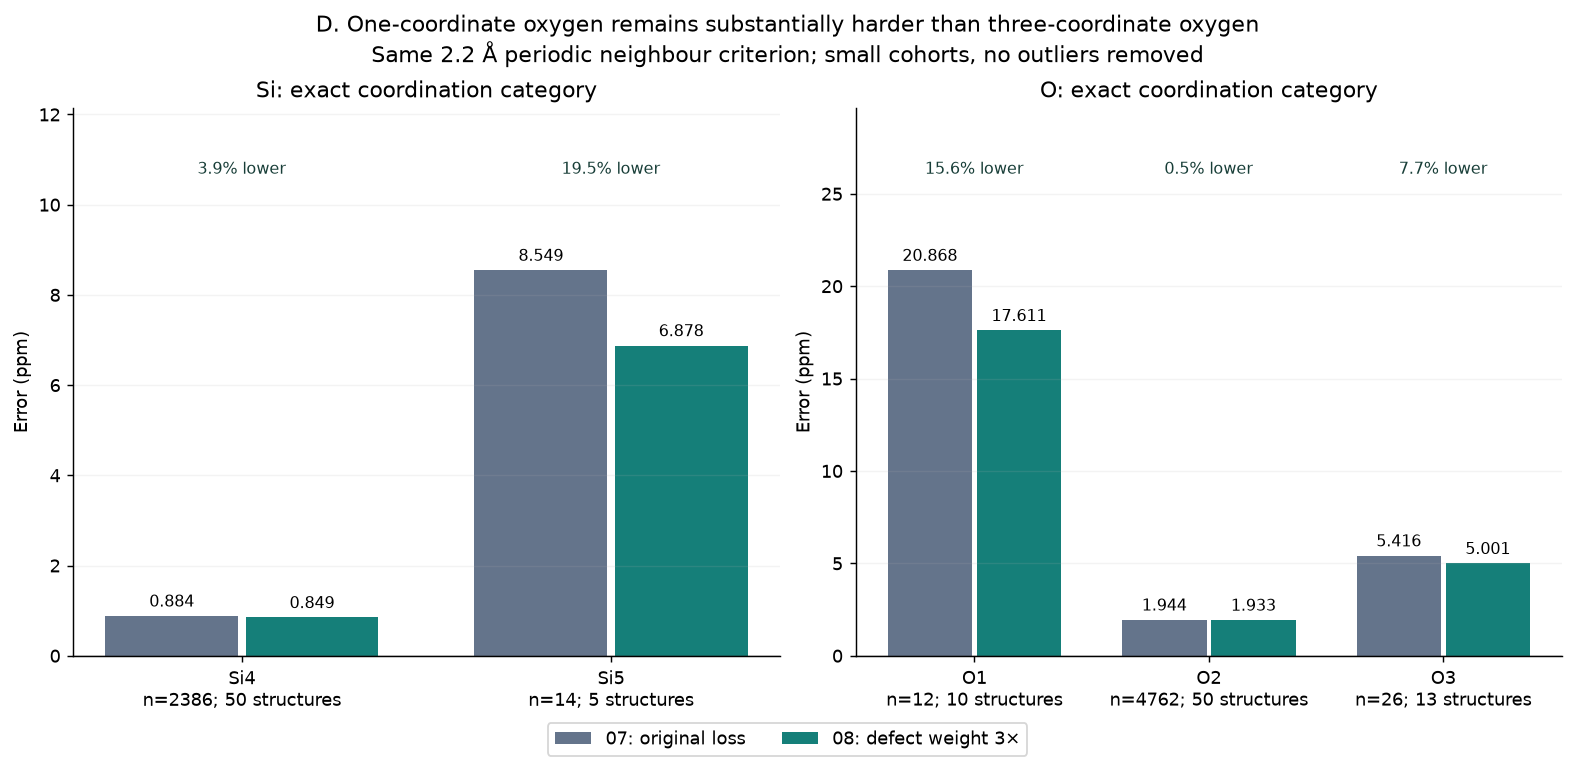

In [14]:
# Decompose actual sums of squared errors, not averages of subgroup RMSEs.
sse_rows=[]
for run,frame in [('07',baseline_sites),('08',coordination_sites)]:
    for (el,group),g in frame.groupby(['element','group']):
        sse_rows.append({'run':run,'element':el,'group':group,'sites':len(g),'SSE_ppm2':float(np.square(g.error_ppm).sum())})
sse_table=pd.DataFrame(sse_rows)
sse_table['percent_of_element_SSE']=100*sse_table.SSE_ppm2/sse_table.groupby(['run','element']).SSE_ppm2.transform('sum')
sse_wide=sse_table.pivot(index=['element','group'],columns='run',values='SSE_ppm2')
sse_wide['SSE_reduction']=sse_wide['07']-sse_wide['08']
sse_wide['percent_of_element_reduction']=100*sse_wide.SSE_reduction/sse_wide.groupby('element').SSE_reduction.transform('sum')
display(sse_table.round(3));display(sse_wide.round(3))
fig,axes=plt.subplots(1,3,figsize=(15,5.8),layout='constrained')
normal_color,defect_color='#6e98b6','#ad4567'
for ax,el in zip(axes[:2],ELEMENTS):
    bottom=np.zeros(2)
    for group,color in [('Common coordination',normal_color),('Other coordination',defect_color)]:
        vals=[float(sse_table.loc[(sse_table.run==run)&(sse_table.element==el)&(sse_table.group==group),'percent_of_element_SSE'].iloc[0]) for run in ['07','08']]
        bars=ax.bar([0,1],vals,bottom=bottom,color=color,label=group)
        ax.bar_label(bars,labels=[f'{v:.1f}%' for v in vals],label_type='center',color='white',fontsize=11)
        bottom+=vals
    ax.set(xticks=[0,1],xticklabels=['07','08'],ylim=(0,100),ylabel='Share of squared error (%)',title=f'{el}: where remaining error sits')
ax=axes[2];bottom=np.zeros(2)
for group,color in [('Common coordination',normal_color),('Other coordination',defect_color)]:
    vals=[sse_wide.loc[(el,group),'percent_of_element_reduction'] for el in ELEMENTS]
    bars=ax.bar([0,1],vals,bottom=bottom,color=color,label=group)
    ax.bar_label(bars,labels=[f'{v:.1f}%' for v in vals],label_type='center',color='white',fontsize=11)
    bottom+=vals
ax.set(xticks=[0,1],xticklabels=ELEMENTS,ylim=(0,100),ylabel='Share of total SSE reduction (%)',title='Which sites supplied the improvement?')
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('C. Defects supply most of the improvement, but normal sites supply most remaining error\nNormal sites make up >99% of each element; error share is not per-site difficulty')
plt.show()

# Keep exact coordination categories separate; pooled O1/O3 can conceal different difficulty.
fig,axes=plt.subplots(1,2,figsize=(12,5.8),layout='constrained')
for ax,el in zip(axes,ELEMENTS):
    b=coordination_detail.loc[el].sort_index();a=baseline_detail.loc[el].reindex(b.index)
    labels=[f'{el}{int(c)}\nn={int(row.sites)}; {int(row.structures)} structures' for c,row in b.iterrows()]
    paired_bars(ax,labels,a.RMSE_ppm,b.RMSE_ppm,f'{el}: exact coordination category')
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('D. One-coordinate oxygen remains substantially harder than three-coordinate oxygen\nSame 2.2 Å periodic neighbour criterion; small cohorts, no outliers removed')
plt.show()


## 13. Follow individual outliers and quantify the limits of the comparison

**Figure E** pairs identical atoms and includes the union of each model's five largest absolute errors per element. It avoids choosing only successful examples. **Figure F** separates structure concentration from tail concentration. In its lower panels, a model can have a higher fraction of squared error in its tail even when its absolute tail errors are smaller, because the denominator changes.

**Figure G** resamples the same 50 structures for both models together, 10,000 times (seed 42), and shows the 95% percentile interval of RMSE₀₈ − RMSE₀₇. It retains within-structure dependence, assumes independent structures, and is conditional on these already-selected checkpoints. It excludes training-seed variability and is not an independent final test. An interval crossing zero limits confidence in a broadly reproducible improvement; it does not undo the observed reduction on the supplied validation set.


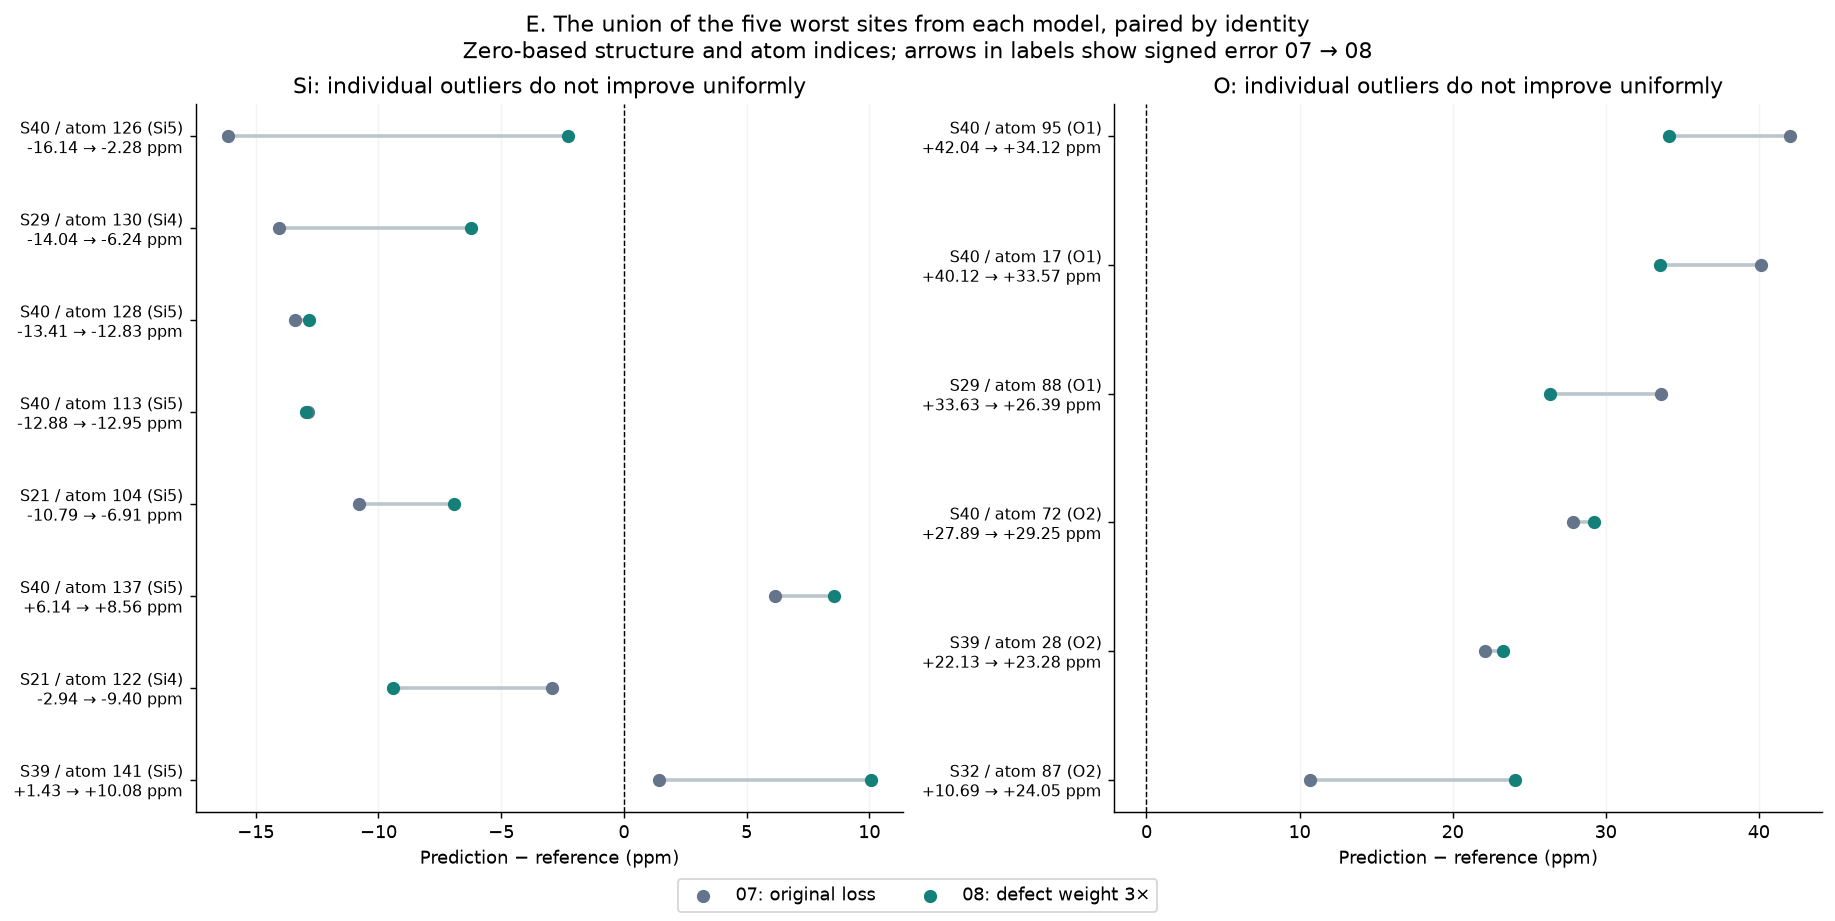

,element,structure_index,atom_index,reference_ppm_07,error_ppm_07,absolute_error_ppm_07,reference_ppm_08,error_ppm_08,absolute_error_ppm_08,opposite_element_neighbours
2,O,29,88,98.1843,33.6337,33.6337,98.1843,26.3852,26.3852,1
4,O,32,87,66.7118,10.6923,10.6923,66.7118,24.0535,24.0535,2
5,O,39,28,108.2200,22.1254,22.1254,108.2200,23.2845,23.2845,2
7,O,40,17,64.1172,40.1175,40.1175,64.1172,33.5712,33.5712,1
8,O,40,72,69.3807,27.8912,27.8912,69.3807,29.2520,29.2520,2
9,O,40,95,52.8293,42.0414,42.0414,52.8293,34.1242,34.1242,1
0,Si,21,104,471.7069,-10.7891,10.7891,471.7069,-6.9105,6.9105,5
1,Si,21,122,418.1029,-2.9411,2.9411,418.1029,-9.3972,9.3972,4
3,Si,29,130,412.0194,-14.0359,14.0359,412.0194,-6.2378,6.2378,4
6,Si,39,141,434.4809,1.4342,1.4342,434.4809,10.0805,10.0805,5


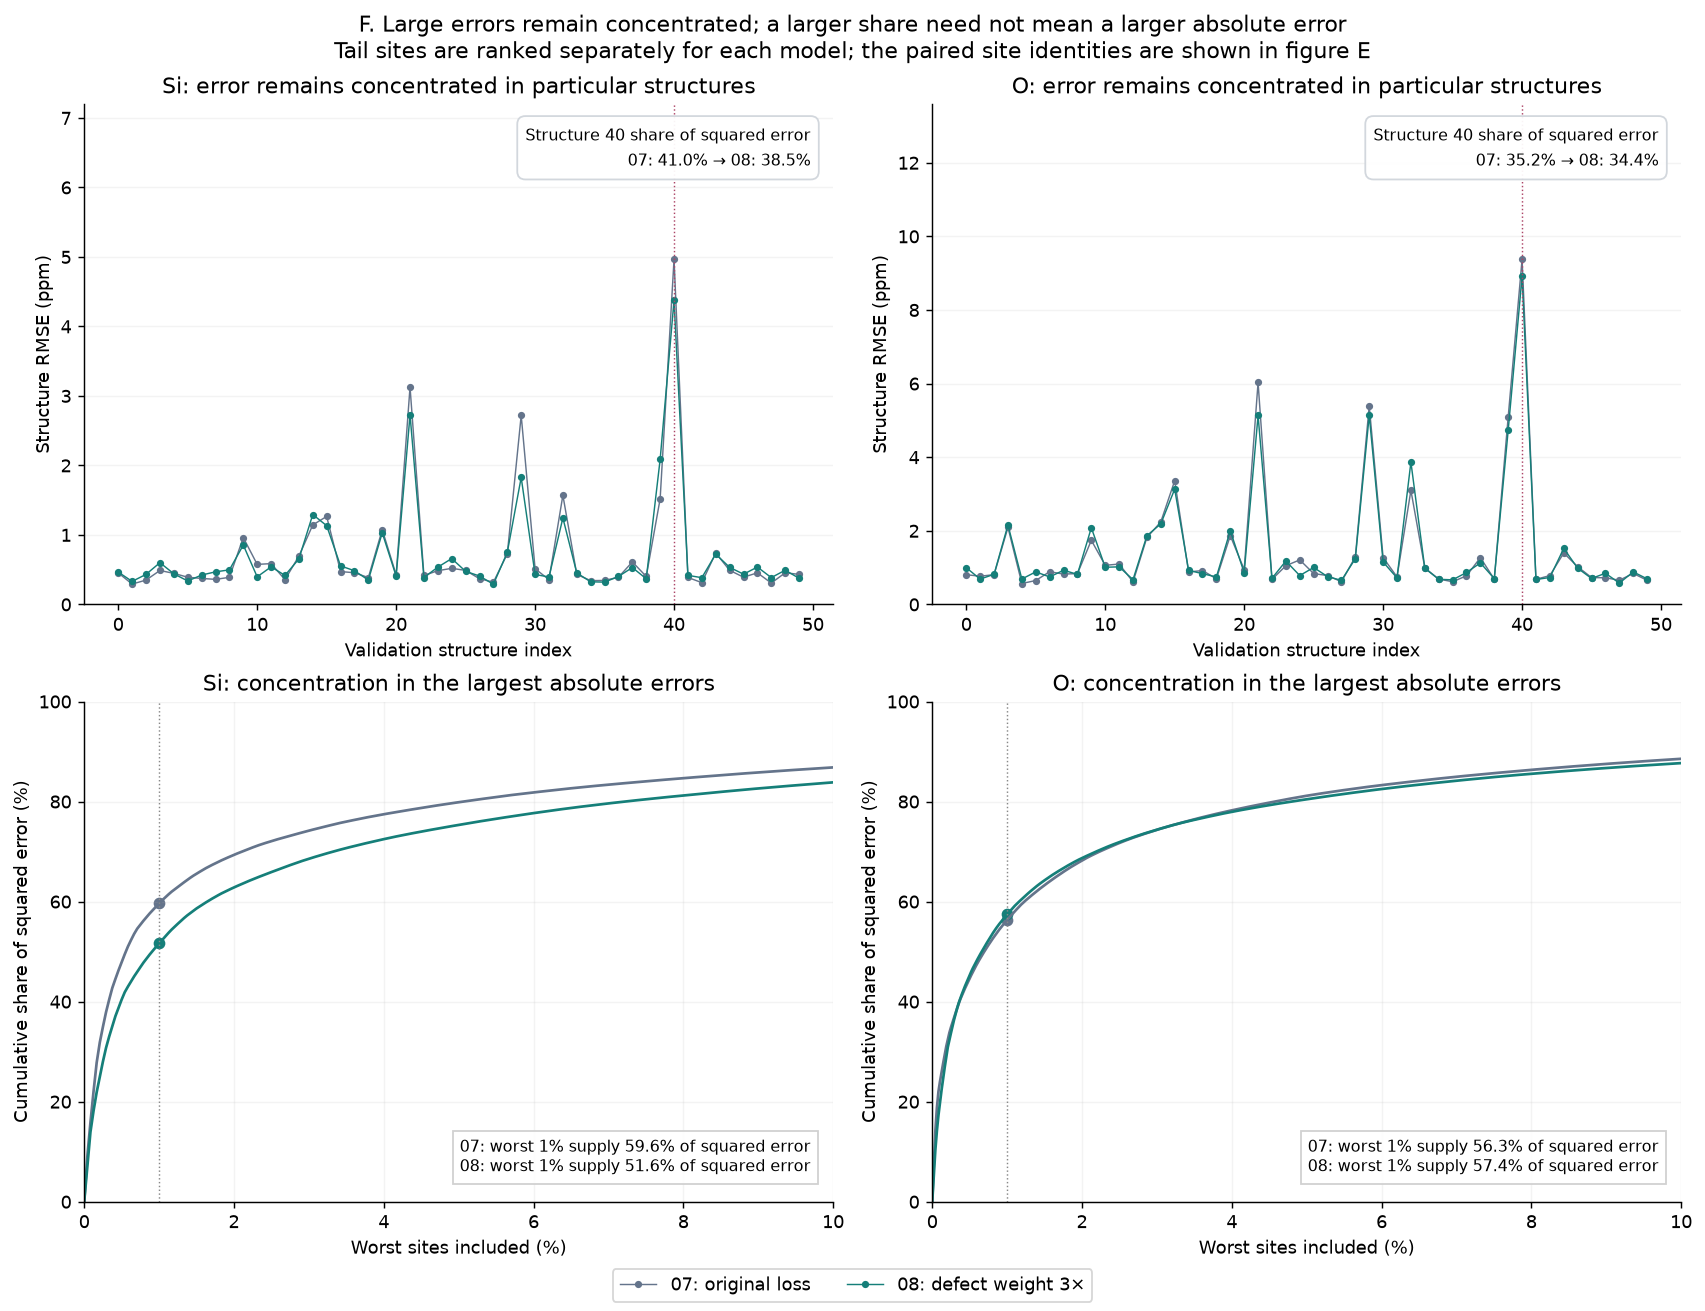

,run,element,top1_count,top1_SSE_pct,structure40_SSE_pct
0,07,Si,24,59.648,40.971
1,08,Si,24,51.641,38.530
2,07,O,48,56.341,35.182
3,08,O,48,57.440,34.409


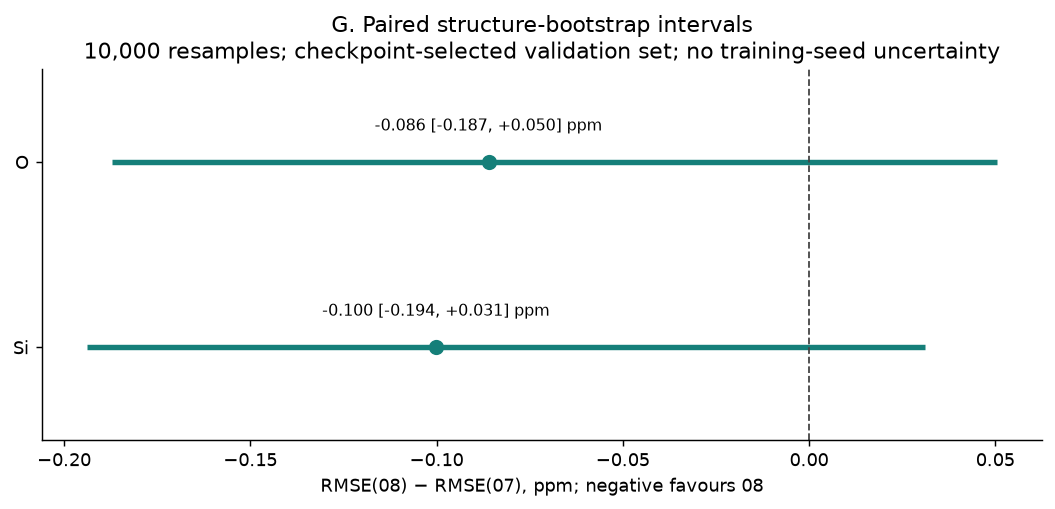

,RMSE_delta_ppm,lower_95_ppm,upper_95_ppm,structures_with_lower_RMSE
element,,,,
Si,-0.1001,-0.1938,0.0310,24
O,-0.0860,-0.1872,0.0504,26


In [15]:
keys=['element','structure_index','atom_index']
paired_sites=baseline_sites[keys+['reference_ppm','error_ppm','absolute_error_ppm']].merge(
    coordination_sites[keys+['reference_ppm','error_ppm','absolute_error_ppm','opposite_element_neighbours']],
    on=keys,suffixes=('_07','_08'),validate='one_to_one')
assert np.array_equal(paired_sites.reference_ppm_07,paired_sites.reference_ppm_08)
# Use the union of both models' five worst sites per element to avoid hand-picking examples.
selected_keys=pd.concat([frame[frame.element.eq(el)].nlargest(5,'absolute_error_ppm')[keys]
    for frame in [baseline_sites,coordination_sites] for el in ELEMENTS]).drop_duplicates()
selected_sites=paired_sites.merge(selected_keys,on=keys,validate='one_to_one')
fig,axes=plt.subplots(1,2,figsize=(14,7),layout='constrained')
for ax,el in zip(axes,ELEMENTS):
    g=selected_sites[selected_sites.element.eq(el)].sort_values('absolute_error_ppm_07',ascending=False)
    y=np.arange(len(g))
    ax.hlines(y,g.error_ppm_07,g.error_ppm_08,color='#bbc5cc',lw=2)
    ax.scatter(g.error_ppm_07,y,color=OLD,s=40,label=RUN_LABELS[0],zorder=3)
    ax.scatter(g.error_ppm_08,y,color=NEW,s=40,label=RUN_LABELS[1],zorder=4)
    labels=[f'S{int(r.structure_index)} / atom {int(r.atom_index)} ({el}{int(r.opposite_element_neighbours)})\n'
            f'{r.error_ppm_07:+.2f} → {r.error_ppm_08:+.2f} ppm' for r in g.itertuples()]
    ax.set_yticks(y,labels,fontsize=9);ax.invert_yaxis();ax.axvline(0,color='black',lw=.8,ls='--')
    ax.set(title=f'{el}: individual outliers do not improve uniformly',xlabel='Prediction − reference (ppm)')
    ax.grid(axis='x',alpha=.15)
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('E. The union of the five worst sites from each model, paired by identity\nZero-based structure and atom indices; arrows in labels show signed error 07 → 08')
plt.show()
display(selected_sites.sort_values(keys).round(4))

# Compare structure concentration and tail concentration separately.
baseline_structure_metrics=pd.DataFrame([
    {'element':el,'structure_index':int(idx),'sites':len(g),**score(g.reference_ppm,g.prediction_ppm)}
    for (el,idx),g in baseline_sites.groupby(['element','structure_index'])])
paired_structures=baseline_structure_metrics.merge(structure_metrics,on=['element','structure_index'],suffixes=('_07','_08'),validate='one_to_one')
tail_rows=[]
fig,axes=plt.subplots(2,2,figsize=(13,10),layout='constrained')
for col,el in enumerate(ELEMENTS):
    g=paired_structures[paired_structures.element.eq(el)].sort_values('structure_index')
    ax=axes[0,col]
    ax.plot(g.structure_index,g.RMSE_ppm_07,'o-',color=OLD,ms=3,lw=.8,label=RUN_LABELS[0])
    ax.plot(g.structure_index,g.RMSE_ppm_08,'o-',color=NEW,ms=3,lw=.8,label=RUN_LABELS[1])
    frame40=g[g.structure_index.eq(40)].iloc[0]
    shares=[]
    for suffix in ['07','08']:
        sse=g[f'sites_{suffix}']*g[f'RMSE_ppm_{suffix}']**2
        shares.append(100*frame40[f'sites_{suffix}']*frame40[f'RMSE_ppm_{suffix}']**2/sse.sum())
    ax.axvline(40,color='#ad4567',lw=.8,ls=':')
    stats_box(ax,f'Structure 40 share of squared error\n07: {shares[0]:.1f}% → 08: {shares[1]:.1f}%',fontsize=9)
    ax.set(title=f'{el}: error remains concentrated in particular structures',xlabel='Validation structure index',ylabel='Structure RMSE (ppm)')
    ax.set_ylim(0,max(g.RMSE_ppm_07.max(),g.RMSE_ppm_08.max())*1.45)
    ax.grid(axis='y',alpha=.15)
    ax=axes[1,col]
    text_lines=[]
    for run,frame,color in [('07',baseline_sites,OLD),('08',coordination_sites,NEW)]:
        errors=frame.loc[frame.element.eq(el),'error_ppm'].to_numpy()
        descending=np.sort(errors**2)[::-1]
        fraction=100*np.arange(1,len(errors)+1)/len(errors)
        cumulative=100*np.cumsum(descending)/descending.sum()
        mask=fraction<=10
        ax.plot(np.r_[0,fraction[mask]],np.r_[0,cumulative[mask]],color=color,label=run)
        n=int(np.ceil(.01*len(errors)));top1=float(cumulative[n-1])
        ax.scatter([100*n/len(errors)],[top1],color=color,s=30)
        text_lines.append(f'{run}: worst 1% supply {top1:.1f}% of squared error')
        tail_rows.append({'run':run,'element':el,'top1_count':n,'top1_SSE_pct':top1,
                         'structure40_SSE_pct':shares[0 if run=='07' else 1]})
    ax.axvline(1,color='#888888',lw=.8,ls=':')
    ax.text(.97,.05,'\n'.join(text_lines),transform=ax.transAxes,ha='right',va='bottom',fontsize=9,
            bbox={'facecolor':'white','alpha':.9,'edgecolor':'#cccccc'})
    ax.set(title=f'{el}: concentration in the largest absolute errors',xlabel='Worst sites included (%)',ylabel='Cumulative share of squared error (%)',xlim=(0,10),ylim=(0,100))
    ax.grid(alpha=.15)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
fig.suptitle('F. Large errors remain concentrated; a larger share need not mean a larger absolute error\nTail sites are ranked separately for each model; the paired site identities are shown in figure E')
plt.show()
tail_comparison=pd.DataFrame(tail_rows)
display(tail_comparison.round(3))

# Paired bootstrap: resample the SAME whole structures for both models.
# This quantifies conditional split sampling variation, not training-seed uncertainty.
paired_rng=np.random.default_rng(42)
paired_draws=paired_rng.integers(0,len(structures['valid']),size=(10000,len(structures['valid'])))
paired_bootstrap_rows=[]
for el in ELEMENTS:
    g=paired_structures[paired_structures.element.eq(el)].sort_values('structure_index')
    assert g.structure_index.to_list()==list(range(len(structures['valid'])))
    estimates={}
    for run in ['07','08']:
        counts=g[f'sites_{run}'].to_numpy()
        sums=counts*g[f'RMSE_ppm_{run}'].to_numpy()**2
        estimates[run]=np.sqrt(sums[paired_draws].sum(axis=1)/counts[paired_draws].sum(axis=1))
    low,high=np.quantile(estimates['08']-estimates['07'],[.025,.975])
    paired_bootstrap_rows.append({'element':el,'RMSE_delta_ppm':metrics.loc[('valid',el),'RMSE_ppm']-baseline_metrics.loc[('valid',el),'RMSE_ppm'],
                                  'lower_95_ppm':low,'upper_95_ppm':high,
                                  'structures_with_lower_RMSE':int((g.RMSE_ppm_08<g.RMSE_ppm_07).sum())})
paired_bootstrap=pd.DataFrame(paired_bootstrap_rows).set_index('element')
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for i,el in enumerate(ELEMENTS):
    r=paired_bootstrap.loc[el]
    ax.hlines(i,r.lower_95_ppm,r.upper_95_ppm,color=NEW,lw=3)
    ax.scatter(r.RMSE_delta_ppm,i,color=NEW,s=55,zorder=3)
    ax.text(r.RMSE_delta_ppm,i+.17,f'{r.RMSE_delta_ppm:+.3f} [{r.lower_95_ppm:+.3f}, {r.upper_95_ppm:+.3f}] ppm',ha='center',fontsize=9)
ax.axvline(0,color='#444444',ls='--',lw=1)
ax.set(yticks=[0,1],yticklabels=ELEMENTS,ylim=(-.5,1.5),xlabel='RMSE(08) − RMSE(07), ppm; negative favours 08',
       title='G. Paired structure-bootstrap intervals\n10,000 resamples; checkpoint-selected validation set; no training-seed uncertainty')
plt.show()
display(paired_bootstrap.round(4))


## 14. Conclusions supported by the figures

1. **Weighting helps the intended cohort in this run (B, C):** most of the decrease in total squared error comes from sites classified as defects. This is consistent with changing optimisation emphasis, but does not prove coordination is the cause of the residuals.
2. **Typical predictions change little (A):** MAE changes are small and median absolute errors increase slightly. The useful gain is concentrated among difficult sites.
3. **The tail is reduced unevenly, not eliminated (A, E, F):** some original outliers improve greatly; others persist or worsen. A lower maximum does not guarantee that every formerly difficult site improved.
4. **Direct coordination alone misses part of the hard population (C, E):** normal-coordinated atoms include large residuals. They may neighbour a defect or have unusual distances/angles; those explanations are hypotheses, not established by these figures.
5. **O1 deserves separate treatment in diagnostics (D):** its remaining error is much higher than O3, despite the same training weight.
6. **The result is encouraging but limited (G):** one training run per objective and small defect cohorts cannot establish seed-to-seed robustness. The validation set already selected the checkpoints and guides development.

These figures do **not** distinguish training-set underfitting from poor generalisation, and do **not** establish missing physics. The next protocol targets exactly that uncertainty.


## 15. Next experiments: fitting difficulty versus generalisation

**Question:** are the remaining errors present even on training environments, or mainly on environments excluded from training? The present validation figures cannot answer this because we have not computed training predictions. A coordination count is a diagnostic grouping, not a complete description of the local environment. The following protocol is a design; no new training has been run.

### Experiment A — Measure the training–validation gap before changing the model

**No retraining and no new loss function.** Evaluate the saved best models from experiments 07 and 08 on **all 800 training structures and the same 50 validation structures**, with `model.eval()` and `torch.no_grad()`. Keep the fitted offsets/scales unchanged and exclude labels from model inputs. Do not open test data. Use fresh predictions and record model/data hashes.

Report the same **unweighted** per-site MAE, RMSE, median, p95, maximum, signed bias and counts on both splits, grouped as:

- Si3, Si4, Si5 (and any other observed Si counts separately).
- O1, O2, O3 (and any other observed O counts separately).
- Within normal Si4/O2: directly bonded to a defect, two bond steps from a defect, or farther away. Use minimum graph distance to any direct defect so groups do not overlap; use the same periodic Si–O <2.2 Å graph. Report site counts and distinct structure counts (not assumed statistically independent), including empty groups.

**Figures:** train/validation RMSE and MAE by exact coordination for both models; residual distributions with sample counts; train/validation errors against shielding and bond distances; normal-site error versus distance to a defect. Add tables of the largest training and validation residuals with stable structure/atom indices. Repeat the *diagnostic grouping only* at 2.1/2.2/2.3 Å to identify sites sensitive to the cutoff; do not select the nicest result or change training weights from this exercise.

**Hypotheses and interpretation**

| Outcome | Interpretation supported | What it does not establish |
|---|---|---|
| Training defect errors are low; validation defect errors are high | Generalisation/coverage is the leading concern; the model can represent at least the training examples | That more weight or more capacity will solve unseen environments |
| Both training and validation defect errors remain high | The current training procedure has not fitted these environments well | Architectural impossibility or missing physics; optimisation, regularisation and labels remain alternatives |
| 08 lowers training defect error substantially but barely lowers validation error | More emphasis mainly improves fitting; transfer to unseen environments is limited | A universal statement about weighting from one seed |
| Normal atoms close to defects are harder than normal atoms farther away | The current direct-coordination mask misses part of the difficult neighbourhood | A causal defect effect, without accounting for other structural differences |

Compare **absolute errors as well as gap ratios**, which become unstable when training error is near zero. Train and validation cohorts are not identical distributions: a gap is evidence to investigate, not a decomposition proving a cause. If the best checkpoint has large training errors, evaluate the final checkpoint too; if it fits training better while validation worsens, checkpoint selection is favouring generalisation over memorisation.

### Experiment B — Can the existing architecture fit a small set of training defects?

Run this if Experiment A shows substantial training errors. This is a **deliberate memorisation probe**, not a new generalisation score.

1. Select **32 complete training structures**, using training labels/geometry only. Use a deterministic, coverage-first selection with seed 42 that includes O1, O3, Si5 and Si3 where available, then fills remaining places by random sampling. Aim for at least eight sites per rare category where feasible; record the actual counts and the selected structure IDs. Do not choose structures by validation errors. Retain every atom and its label in each selected structure, including normally coordinated controls.
2. Initialise two arms from **the exact same experiment-08 best weights**, including the current offsets and scales. Use a fresh optimizer/scheduler, all parameters trainable and no pre-fit/recentring step. Arm B1 uses `defect_weight: 1.0`; arm B3 uses `defect_weight: 3.0`. Keep the geometry cutoff at 6 Å and coordination cutoff at 2.2 Å. This makes the weighting the only difference between the two arms.
3. Use AdamW, **learning rate 1e-4, weight decay 0**, physical batch size 1 and gradient accumulation 4, float32, identical ordering/seeds and architecture. Disable stochastic regularisation if present in both arms. Start with a fixed **5,000 optimizer updates** per arm; show curves versus optimizer updates, not epochs. No validation-based early stopping. Save the final model and checkpoints at a fixed interval, e.g. every 250 updates; choose any diagnostic “best fit” checkpoint using training errors only and label that choice explicitly. If loss is still declining at the budget, the probe is inconclusive; extend both arms by the same predeclared update budget.
4. At checkpoints, compute **unweighted training errors** on the selected structures, separately for every coordination category and normal controls. Plot group RMSE, p95 and maximum versus updates, and show a residual plot at the end. The weighted objective is also logged but is not the accuracy comparison.

**The loss stays the same mathematical family.** For minibatch B, predicted absolute isotropic shielding $\hat\sigma_i$, reference $\sigma_i$, and the original 2.2 Å coordination criterion:

$$d_i=\mathbf{1}\{(Z_i=\mathrm{Si}\land c_i\ne4)\ \lor\ (Z_i=\mathrm{O}\land c_i\ne2)\},\qquad w_i=1+(\alpha-1)d_i,$$

$$L_{\rm train}=1000\,\frac{\sum_{i\in B}w_i(\hat\sigma_i-\sigma_i)^2}{\sum_{i\in B}w_i},\qquad \alpha\in\{1,3\}.$$

The outer **1000 is retained from experiments 07/08 solely to keep the objective/gradient scale consistent**. It does not preferentially weight defects and is not a physical coefficient or a ppm conversion. Do not change it at the same time as the experiment. With α=1 this reduces to ordinary MSE. The denominator is the sum of weights in the current minibatch, as in `coordination_loss.py`; the average logged training objective should not be mistaken for a globally normalised, all-dataset weighted MSE.

Both arms can use the **existing** custom class. The only loss-setting difference is:

```yaml
loss:
  isotropy:
    +nmr_helpers.coordination_loss.CoordinationWeightedMSE:
      defect_weight: 3.0  # B3; use 1.0 for B1
      coordination_cutoff: 2.2
      weight: 1000.0
```

This block defines the loss only. A runnable probe configuration also needs a checkpoint-initialisation path and the selected training subset; loading weights must not rerun the helper's pre-fit routine. Do not accidentally resume the old optimizer, scheduler, or update counter. Check that both arms' starting predictions are identical before training.

The existing class returns ordinary MSE when `model.training` is false. Nevertheless, report MAE/RMSE directly from prediction residuals to avoid confusion with the outer factor of 1000. There is **no energy/force loss, Huber loss, or new physics penalty** in this probe: those would introduce additional explanations for its outcome.

**Hypotheses and decision rules**

- **B1 and B3 both fit the selected defects accurately:** a broad claim that the architecture cannot represent these training environments is weakened. The full-data problem is more likely a trade-off in optimisation/capacity allocation or coverage/generalisation. Memorising 32 structures does not establish the required locality or physics on unseen structures.
- **B3 fits the defects much better than B1:** relative training emphasis matters on this subset; examine whether normal control errors rise. It does not yet justify increasing α in the production model.
- **Both retain large, persistent errors:** first check labels, normalisation, gradients and learning-rate sensitivity. Only then test capacity or descriptor/context changes, one at a time. Failure at one optimisation budget is not proof that the architecture cannot fit the data.
- **Rare groups improve but normal controls worsen:** an accuracy trade-off is present. Record it rather than claiming the defects are fixed from a single group-average metric.

“Fits accurately” should be reported as actual ppm errors and reduction factors; a **10× drop in defect RMSE** is a useful predeclared diagnostic target, not a justified DFT noise floor. Also require the p95/max curves to improve so one or two sites cannot hide behind a low mean. If the curves keep falling, report an unfinished optimisation probe rather than an inability to fit.

### Experiment C — Conditional follow-up if the evidence points to generalisation

Hold the architecture and the α=3 loss fixed. Build **nested training-only datasets** with the same number of normal-only structures and increasing numbers of complete structures containing defects (e.g. 25%, 50%, 100% of the available defect-bearing structures). Choose membership using training geometry only. Within each seed, start all arms from the **same fresh random model weights**, not from a checkpoint already trained on the full dataset: otherwise the supposedly omitted environments have already influenced the model. Fit the initial elemental offsets/scales on the shared base training structures only and reuse that initialisation across arms. Use matched optimizer-update budgets. Repeat model/subset/order seeds (e.g. 42, 43, 44), keeping nested membership and identical initial weights across arms within each seed. Report the actual counts for each rare category and each structure source; include a normal-structure addition control of comparable size to distinguish adding rare environments from adding data generally.

The validation split stays fixed, with no validation structures added to training. Plot validation RMSE for O1, O3, Si5 and normal controls versus the number of training structures supporting each group. A consistent reduction as distinct training defect environments increase supports a coverage limitation. A flat curve could reflect insufficient structural diversity or another limitation; it does not prove that extra data cannot help. This learning curve uses existing data and therefore tests reduced coverage up to current coverage, not the benefit of uncollected structures beyond the dataset.

If genuinely new data are later generated, specify new sampling from training-side coverage gaps and keep the original validation structures out of training. Energy/force transfer learning remains a separate experiment: it changes the representation/initialisation and should not be combined with these diagnostic changes before their individual effects are understood.

**Recommended order:** run A first. Run B if training defects are also poorly fitted; prioritise C if training defects are already fitted well. Only after locating the limitation should we change the production objective, widen the defect mask to neighbours, increase capacity, or compare energy/force initialisation. All of these remain development experiments; this validation set has already influenced checkpoint and experiment selection.
